# [Respiratory Symptoms and Treatment](https://www.kaggle.com/datasets/abbotpatcher/respiratory-symptoms-and-treatment/data)

**Objetivo.** Decidir, com evidência reproduzível, se a base Respiratory Symptoms and Treatment pode servir de semente para o sistema de recomendação de intervenções da REDE HU+ ou se é inadequada para uso clínico.

**Estrutura (Detalhamento Técnico):**

| # | Etapa | O que se responde |
|---|---|---|
| 1 | **Acessar e caracterizar** | Procedência (quem, real/sintético, licença), variáveis, qualidade, consistência, duplicatas |
| 2 | **Testar** | Mapeamento de sintomas, doenças e tratamentos para CID-10 / SNOMED CT + ingestão de teste na camada bronze |
| 3 | **Analisar** | Serve de semente? Teste de recomendador base + scorecard + veredito |
| 4 | **Lacunas candidatas** | Terminologia respiratória em PT, critérios mínimos de procedência, bases clínicas validadas |



## 0. Configuração do ambiente

Importam-se as bibliotecas, definem-se os caminhos e o estilo gráfico, e declara-se a **ficha de procedência**

In [5]:
!pip install -q kagglehub[pandas-datasets]

In [6]:
import os, re, json, glob, hashlib, shutil, datetime as dt, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display, Markdown
import time
import kagglehub
from kagglehub import KaggleDatasetAdapter
warnings.filterwarnings("ignore")

In [7]:
# Estilo visual dos gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
# Semente
SEED = 42

# Configuração do Kaggle
path = kagglehub.dataset_download("abbotpatcher/respiratory-symptoms-and-treatment")
print("Dataset baixado em:", path)
for root, _, files in os.walk(path):
    for f in files:
        print(os.path.join(root, f))


# FICHA DE PROCEDÊNCIA --> None: "sem evidência".
PROCEDENCIA = dict(
    autor_publicador          = "American Health Info",
    plataforma_url            = "https://www.kaggle.com/datasets/abbotpatcher/respiratory-symptoms-and-treatment",
    licenca                   = "Open Database License (ODbL) para a base de dados; Database Contents License para o seu conteúdo",
    fecha_publicacion         = "2021-04-16",
    version                   = "Versão 5 (arquivo: respiratory symptoms and treatment.csv, 2.3 MB)",
    declara_sintetico         = None,   # O autor declara coleta de um departamento de saúde pública; não declara que seja sintético.
    metodologia_documentada = True,    # Descreve fonte (departamento de saúde pública de Albuquerque/NM), variáveis e frequência de atualização, embora sem protocolo detalhado.
    institucion_o_etica     = None,    # Menciona agradecimento ao departamento de saúde pública do Novo México, mas não identifica instituição responsável nem aprovação ética/CEP.
    validacion_clínica      = False,   # Não há evidência de revisão clínica nem referência a diretrizes clínicas na documentação do dataset.
)

# Pastas de saída
OUT = "outputs"
FIGS = os.path.join(OUT, "figs")
LAKE = "datalake"
# Criar as pastas se não existirem
for d in (OUT, FIGS, LAKE):
    os.makedirs(d, exist_ok=True)

# Formato para salvar figura
def guardar(fig, nombre):
    fig.savefig(os.path.join(FIGS, nombre + ".png"), bbox_inches="tight", dpi=130)
    plt.show()

# Formato para salvar tabela
def tabla(df_, nombre, index=True):
    df_.to_csv(os.path.join(OUT, nombre + ".csv"), index=index, encoding="utf-8-sig")
    return df_

print("Saídas em:", os.path.abspath(OUT))

Using Colab cache for faster access to the 'respiratory-symptoms-and-treatment' dataset.
Dataset baixado em: /kaggle/input/respiratory-symptoms-and-treatment
/kaggle/input/respiratory-symptoms-and-treatment/respiratory symptoms and treatment.csv
Saídas em: /content/outputs


# 1. Acessar e caracterizar

Acessa-se a base e caracteriza-se em quatro frentes: (1.1) volumetria e variáveis, (1.2) procedência, (1.3) qualidade e duplicatas, (1.4) consistência clínica.



## 1.1 Acesso e volumetria

Localiza-se o CSV, calcula-se sua pegada **SHA-256** e descrevem-se as 6 variáveis.

In [8]:
# Localizar o arquivo CSV dentro do caminho baixado pelo kagglehub
csv_files = [f for f in glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)]
if not csv_files:
    raise FileNotFoundError("Nenhum arquivo CSV foi encontrado no download do Kaggle.")
CSV_PATH = csv_files[0]

# Cálculo do hash SHA-256 (demonstra a fidelidade da camada bronze em relação ao original)
SHA256 = hashlib.sha256(open(CSV_PATH, "rb").read()).hexdigest()
df_raw = pd.read_csv(CSV_PATH) # Lê-se tal qual: fonte para a camada bronze

print(f"Arquivo : {CSV_PATH}")
print(f"SHA-256 : {SHA256}")
print(f"Tamanho : {df_raw.shape[0]:,} linhas x {df_raw.shape[1]} colunas")
print('')

display(df_raw.head())
print('')

# Dicionário de variáveis
diccionario = pd.DataFrame({
    "type_pandas": df_raw.dtypes.astype(str),
    "rol": ["Variável de entrada (sintoma, texto livre)", "Variável de entrada (anos)", "Variável de entrada",
            "Rótulo diagnóstico", "Intervenção (objetivo do recomendador)", "Gravidade (low/medium/high)"],
    "examples": [", ".join(map(str, df_raw[c].dropna().unique()[:3])) for c in df_raw.columns],
})
display(diccionario)

Arquivo : /kaggle/input/respiratory-symptoms-and-treatment/respiratory symptoms and treatment.csv
SHA-256 : a88edab166baa44e974c8a00e4cc4965867c923a7c8871afe33f40a9e6e39226
Tamanho : 38,537 linhas x 6 colunas



,Symptoms,Age,Sex,Disease,Treatment,Nature
0,coughing,5.0,female,Asthma,Omalizumab,high
1,tight feeling in the chest,4.0,female,Asthma,Mepolizumab,high
2,wheezing,6.0,male,Asthma,Mepolizumab,high
3,shortness of breath,7.0,male,Asthma,Mepolizumab,high
4,shortness of breath,9.0,male,Asthma,Mepolizumab,high


,type_pandas,rol,examples
Symptoms,object,"Variável de entrada (sintoma, texto livre)","coughing , tight feeling in the chest, wheezing"
Age,float64,Variável de entrada (anos),"5.0, 4.0, 6.0"
Sex,object,Variável de entrada,"female, male, not to say"
Disease,object,Rótulo diagnóstico,"Asthma, Bronchiectasis, bronchiolitis"
Treatment,object,Intervenção (objetivo do recomendador),"Omalizumab, Mepolizumab, itraconazole"
Nature,object,Gravidade (low/medium/high),"high, medium, low"


O CSV original foi carregado sem alterações e seu SHA-256 foi calculado. A tabela acima é o **dicionário de dados que a base traz**: Symptoms (sintoma em texto livre), Age, Sex, Disease (diagnóstico), Treatment (intervenção) e Nature (gravidade). Em execuções anteriores, a base tem **38.537 linhas × 6 colunas**.

O que *não* existe: identificador de paciente, data, centro de saúde nem códigos padrão.

## 1.2 Auditoria de procedência
Responde *quem a gerou, se é real ou sintética e com qual licença*. Há dois tipos de evidência:

1. **Declarada** (autor, licença, método): só pode vir da página de origem $\rightarrow$ lê-se a partir da ficha `PROCEDENCIA`.
2. **Inferida a partir dos próprios dados** (pegadas típicas de dados sintéticos): calculam-se indicadores objetivos. São **indícios, não provas**.

In [9]:
cols = [c.lower() for c in df_raw.columns]
tiene_id    = any(re.search(r"(^id$|_id$|patient|paciente|record|registro)", c) for c in cols)
tiene_fecha = any(re.search(r"(date|fecha|data_|timestamp|year|^ano$)", c) for c in cols)
tiene_sitio = any(re.search(r"(hospital|clinic|site|centro|unidade|region|city|country)", c) for c in cols)

dis = df_raw["Disease"].astype("string").str.strip().str.lower()
p = dis.value_counts(normalize=True)
bloque_obs  = (dis == dis.shift()).mean() # prob. de que a linha seguinte tenha a mesma doença
bloque_esp  = float((p**2).sum()) # o esperável se as linhas estivessem misturadas ao acaso
mismo = (dis == dis.shift())
paso_edad = (df_raw["Age"].diff().abs() <= 1)[mismo].mean()   # idades "em escada" dentro de um bloco
dup_pct = df_raw.duplicated().mean()

# tratamento quase determinado pela doença: % de linhas cujo tratamento é o mais frequente da sua doença
tr = df_raw["Treatment"].astype("string").str.strip().str.lower()
modal = (pd.DataFrame({"d": dis, "t": tr}).dropna().groupby("d")["t"]
         .agg(lambda s: s.value_counts(normalize=True).iloc[0]))

indicios = pd.DataFrame([
    ["Linhas duplicadas exatas > 50 %",                              f"{dup_pct:.1%}",                                    dup_pct > .5],
    ["Ordem em blocos (obs./esperado > 5)",                         f"{bloque_obs:.2f} vs {bloque_esp:.2f} ({bloque_obs/bloque_esp:.1f})", bloque_obs/bloque_esp > 5],
    ["Idades consecutivas em escada > 50%",                          f"{paso_edad:.1%}",                                  paso_edad > .5],
    ["Sem identificador, data nem local",                          f"id={tiene_id}, data={tiene_fecha}, local={tiene_sitio}", not (tiene_id or tiene_fecha or tiene_sitio)],
    ["A mediana das porcentagens do tratamento modal por doença > 50%", f"{modal.median():.1%}", modal.median() > .5],
], columns=["Indício de geração sintética / modelo", "Valor medido", "Cumpre"])
display(indicios)

n_ind = int(indicios["Cumpre"].sum())
print(f"\n>>> {n_ind} de {len(indicios)} indícios presentes. Isto é uma suspeita forte de dados gerados por modelo/sintéticos, ")
print("    NÃO uma prova: a prova só pode vir do autor (declaração) ou da metodologia publicada.")
print('')

ficha = pd.DataFrame([(k, v if v is not None else "sem evidência") for k, v in PROCEDENCIA.items()],
                     columns=["Campo de procedência", "Valor registrado"])
tabla(ficha, "procedencia_ficha", index=False)

,Indício de geração sintética / modelo,Valor medido,Cumpre
0,Linhas duplicadas exatas > 50 %,97.7%,True
1,Ordem em blocos (obs./esperado > 5),0.98 vs 0.09 (11.5),True
2,Idades consecutivas em escada > 50%,26.8%,False
3,"Sem identificador, data nem local","id=False, data=False, local=False",True
4,A mediana das porcentagens do tratamento modal...,83.7%,True



>>> 4 de 5 indícios presentes. Isto é uma suspeita forte de dados gerados por modelo/sintéticos, 
    NÃO uma prova: a prova só pode vir do autor (declaração) ou da metodologia publicada.



,Campo de procedência,Valor registrado
0,autor_publicador,American Health Info
1,plataforma_url,https://www.kaggle.com/datasets/abbotpatcher/r...
2,licenca,Open Database License (ODbL) para a base de da...
3,fecha_publicacion,2021-04-16
4,version,Versão 5 (arquivo: respiratory symptoms and tr...
5,declara_sintetico,sem evidência
6,metodologia_documentada,True
7,institucion_o_etica,sem evidência
8,validacion_clínica,False


**Base metodológica**

* **Marcos de qualidade de dados:** Kahn et al. (2016) (*Plausibilidade, Unicidade, Completude*) e ISO/IEC 25012 (*Completude, Consistência, Rastreabilidade*).
* **Documentação e procedência:** Gebru et al. (2018) (*Datasheets for Datasets* para rastreabilidade e metadados).
* **Detecção forense:** Bradshaw & Payne (2021) (detecção de fabricação e padrões anômalos em dados tabulares).

**Explicação e conclusão**

* **Contraste (Declarado vs. Medido):** A plataforma indica procedência institucional sem advertir origem sintética; no entanto, as métricas internas revelam uma *assinatura de modelo* inequívoca (duplicados massivos, blocos rígidos por doença, idades em escada e ausência total de rastreabilidade).
* **Critério de Coerência:** O fato de que `declara_sintetico = False` *não constitui um ponto a favor*, mas sim uma contradição com a evidência técnica. Ao chocar a declaração com padrões de fabricação impossíveis em pacientes reais, o dataset é catalogado para efeitos de risco como **não verificável, equivalente a sintético**.

## 1.3 Qualidade: nulos, formato, duplicados
(a) perfil de nulos e tipos, (b) variantes de escrita do mesmo valor (maiúsculas, espaços, ponto final, erros de digitação), (c) limpeza conservadora em um DataFrame `df` (sem imputar: os vazios passam a `sem dado`), (d) contagem de duplicatas em diferentes níveis.

In [10]:
def norm_txt(s):
    return (s.astype("string").str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
             .str.rstrip(".").str.strip().replace({"": pd.NA, "nan": pd.NA, "none": pd.NA}))

TXT = ["Symptoms", "Disease", "Treatment", "Sex", "Nature"]
df = df_raw.copy()
for c in TXT: df[c] = norm_txt(df[c])

CORR_TRAT = {"antibiotic": "antibiotics", "inhealer": "inhaler", "oxyzen": "oxygen", "consult doctor": "consult a doctor"}
df["Treatment"] = df["Treatment"].replace(CORR_TRAT)
df["Sex"] = df["Sex"].replace({"not to say": "no declara"})
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

#(a) nulos e tipos
nulos = pd.DataFrame({"tipo": df_raw.dtypes.astype(str), "nulos": df_raw.isna().sum(),
                      "% nulos": (100*df_raw.isna().mean()).round(2)})
# em 'Nature' há células com um espaço ' ' que NÃO contam como nulo no formato bruto: medem-se à parte
vacios_ocultos = {c: int((df_raw[c].astype("string").str.strip() == "").sum()) for c in TXT}
nulos["vazios ocultos (' ')"] = pd.Series(vacios_ocultos)
nulos["% real vazio"] = (100*(df.isna().sum()/len(df))).round(2)
display(nulos)
print('')

#(b) variantes de escrita
var = pd.DataFrame({"únicos em bruto": df_raw[TXT].nunique(), "únicos após normalizar": df[TXT].nunique()})
var["valores 'redundantes' eliminados"] = var.iloc[:, 0] - var.iloc[:, 1]
display(var)
print('')

#(d) duplicatas em níveis
niveles = pd.Series({
    "1. Linhas brutas": len(df_raw),
    "2. Únicas exatas (bruto)": len(df_raw.drop_duplicates()),
    "3. Únicas após normalizar texto": len(df.drop_duplicates()),
    "4. Perfis sem Age (5 variáveis-chave)": len(df[TXT].drop_duplicates()),
})
display(niveles)

,tipo,nulos,% nulos,vazios ocultos (' '),% real vazio
Symptoms,object,696,1.81,0.0,1.81
Age,float64,342,0.89,NaN,0.89
Sex,object,922,2.39,0.0,2.39
Disease,object,340,0.88,0.0,0.88
Treatment,object,2841,7.37,0.0,7.37
Nature,object,2190,5.68,24.0,5.75


,únicos em bruto,únicos após normalizar,valores 'redundantes' eliminados
Symptoms,92,77,15
Disease,18,18,0
Treatment,33,26,7
Sex,3,3,0
Nature,4,3,1


,0
1. Linhas brutas,38537
2. Únicas exatas (bruto),903
3. Únicas após normalizar texto,901
4. Perfis sem Age (5 variáveis-chave),429


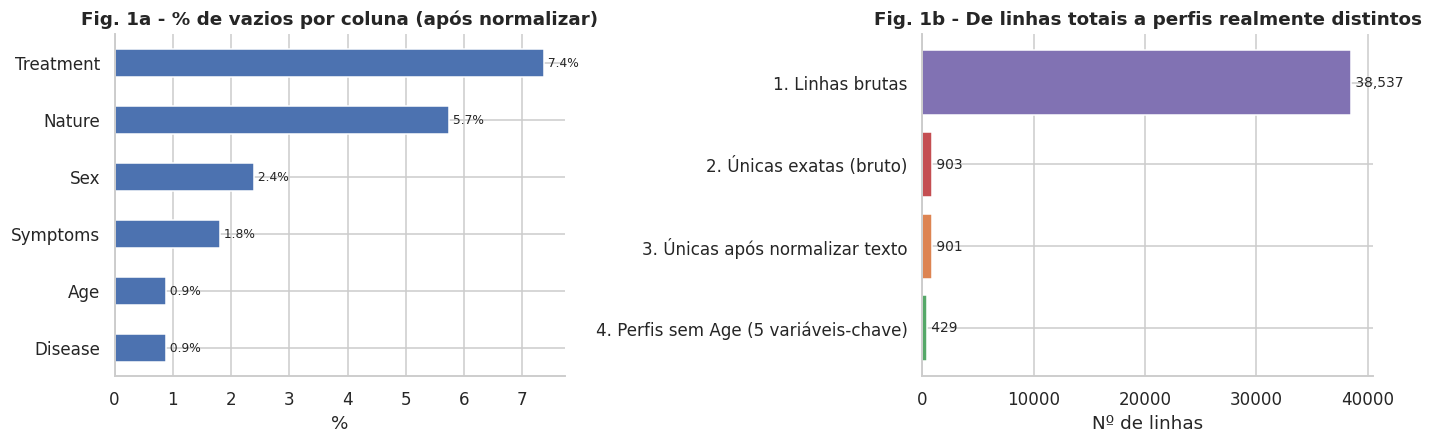


LEITURA -> 37,634 linhas duplicadas exatas (97.7%), apenas 903 linhas são distintas.
Coluna com mais vazios: Treatment (7.4%).


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
(100*df.isna().mean()).sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Fig. 1a - % de vazios por coluna (após normalizar)"); ax[0].set_xlabel("%")
for i, v in enumerate((100*df.isna().mean()).sort_values()): ax[0].text(v, i, f" {v:.1f}%", va="center", fontsize=8)

cols_n = ["#8172B3", "#C44E52", "#DD8452", "#55A868"]
ax[1].barh(niveles.index[::-1], niveles.values[::-1], color=cols_n[::-1])
for i, v in enumerate(niveles.values[::-1]): ax[1].text(v, i, f" {v:,}", va="center", fontsize=9)
ax[1].set_title("Fig. 1b - De linhas totais a perfis realmente distintos"); ax[1].set_xlabel("Nº de linhas")
fig.tight_layout(); guardar(fig, "fig01_nulos_y_duplicados")

print('')
dup_exact = len(df_raw) - len(df_raw.drop_duplicates())
print(f"LEITURA -> {dup_exact:,} linhas duplicadas exatas ({dup_exact/len(df_raw):.1%}), apenas {niveles.iloc[1]:,} linhas são distintas.")
print(f"Coluna com mais vazios: {df.isna().mean().idxmax()} ({100*df.isna().mean().max():.1f}%).")

### Demografia e (Nature) gravidade:

Comparam-se idade, sexo e Nature ('Gravidade da doença') calculados sobre **todas as linhas** em relação aos **perfis únicos**.

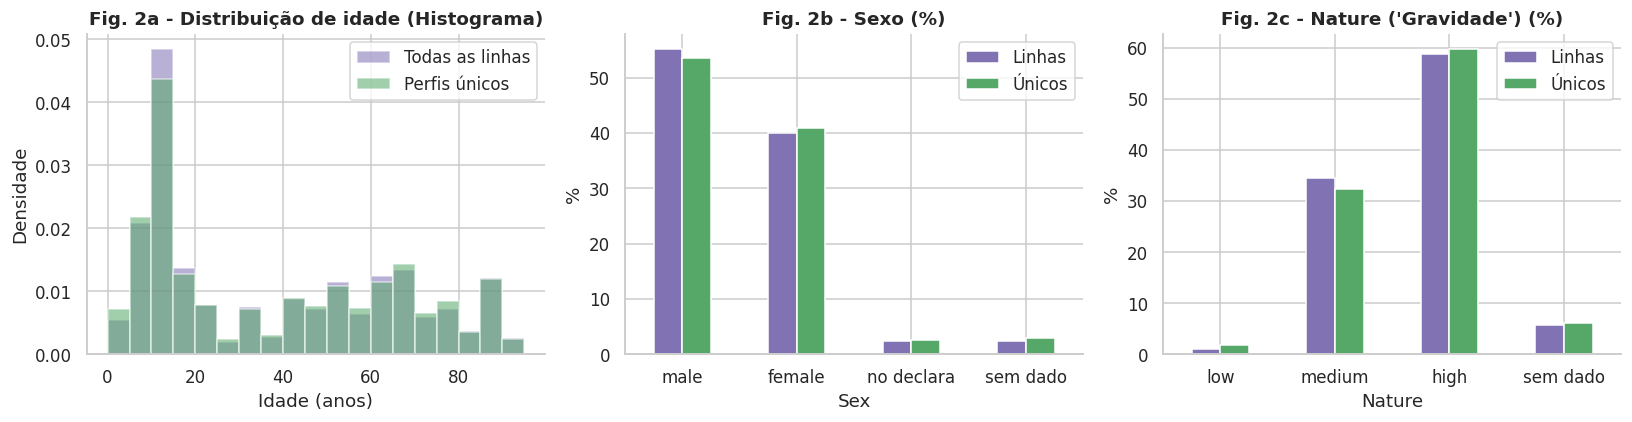


LEITURA AUTOMÁTICA -> idade mediana: linhas = 30.0 | únicos = 33.0
Gravidade 'high': linhas = 58.7% | únicos = 59.7%


In [12]:
uni = df.drop_duplicates()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
bins = np.arange(0, 100, 5)
ax[0].hist(df["Age"].dropna(), bins=bins, alpha=.55, density=True, label="Todas as linhas", color="#8172B3")
ax[0].hist(uni["Age"].dropna(), bins=bins, alpha=.55, density=True, label="Perfis únicos", color="#55A868")
ax[0].set_title("Fig. 2a - Distribuição de idade (Histograma)"); ax[0].set_xlabel("Idade (anos)"); ax[0].set_ylabel("Densidade"); ax[0].legend()

def pct(d, c): return (100*d[c].fillna("sem dado").value_counts(normalize=True))
sx = pd.concat([pct(df, "Sex").rename("Linhas"), pct(uni, "Sex").rename("Únicos")], axis=1).fillna(0)
sx.plot.bar(ax=ax[1], color=["#8172B3", "#55A868"], rot=0); ax[1].set_title("Fig. 2b - Sexo (%)"); ax[1].set_ylabel("%")

ng = pd.concat([pct(df, "Nature").rename("Linhas"), pct(uni, "Nature").rename("Únicos")], axis=1).fillna(0).reindex(["low", "medium", "high", "sem dado"])
ng.plot.bar(ax=ax[2], color=["#8172B3", "#55A868"], rot=0); ax[2].set_title("Fig. 2c - Nature ('Gravidade') (%)"); ax[2].set_ylabel("%")
fig.tight_layout(); guardar(fig, "fig02_demografia_filas_vs_unicos")

print('')
print("LEITURA AUTOMÁTICA -> idade mediana: linhas =", df["Age"].median(), "| únicos =", uni["Age"].median())
print("Gravidade 'high': linhas = %.1f%% | únicos = %.1f%%" % (pct(df, "Nature").get("high", 0), pct(uni, "Nature").get("high", 0)))

A base de dados muda radicalmente dependendo de se contarmos as linhas infladas ou os perfis únicos. No entanto, a sobreposição das distribuições mostra que a duplicação é uniforme: ela não altera o perfil demográfico, apenas infla o número de linhas.

## 1.4 Tamanho efetivo de amostra por doença

Para cada doença, compara-se o nº de linhas com o nº de perfis distintos. Esta é a medida honesta de "quanta informação independente" existe por diagnóstico.

,linhas,perfis_unicos,fator_duplicacao
Disease,,,
pneumonia,6144,124,49.5
bronchitis,4925,87,56.6
chronic obstructive pulmonary disease,3888,81,48.0
mesothelioma,3216,64,50.2
pneumothorax,2880,60,48.0
bronchiolitis,2650,93,28.5
chronic bronchitis,2016,36,56.0
bronchiectasis,1950,71,27.5
influenza,1872,39,48.0


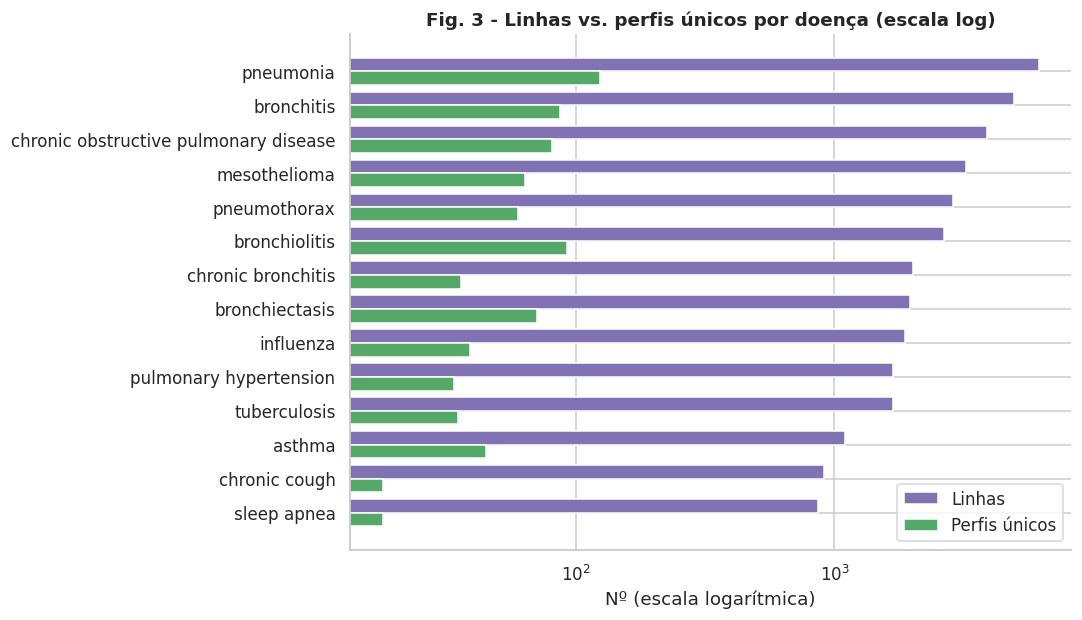

In [13]:
ef = pd.DataFrame({"linhas": df["Disease"].value_counts(), "perfis_unicos": uni["Disease"].value_counts()}).fillna(0).astype(int)
ef["fator_duplicacao"] = (ef["linhas"]/ef["perfis_unicos"].replace(0, np.nan)).round(1)
ef = ef.sort_values("linhas", ascending=False)
display(ef)
print('')

top = ef.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.8))
y = np.arange(len(top))
ax.barh(y + .2, top["linhas"], .4, label="Linhas", color="#8172B3")
ax.barh(y - .2, top["perfis_unicos"], .4, label="Perfis únicos", color="#55A868")
ax.set_yticks(y); ax.set_yticklabels(top.index); ax.set_xscale("log"); ax.legend(loc="lower right")
ax.set_title("Fig. 3 - Linhas vs. perfis únicos por doença (escala log)"); ax.set_xlabel("Nº (escala logarítmica)")
fig.tight_layout(); guardar(fig, "fig03_tamano_efectivo")

- O eixo é logarítmico, portanto cada salto visual de uma linha para outra multiplica por 10 o volume de registros clonados.
- A brecha roxo–verde é o **fator de duplicação** de cada doença.

### 1.4.1 Como se repetem os perfis (replicação em lotes)

Além de contar duplicadas, mede-se **como** elas se repetem: (a) quantas cópias tem cada perfil exato (b) a que distância, na ordem do arquivo, reaparece cada cópia (c) se as idades se repetem e se sobem "em escada" ao longo do arquivo.

(a) 97.3% dos perfis exatos aparecem 24k ou 24k+1 vezes. Cópias por perfil mais comuns:
cópias
48    530
25    188
24     79
49     60
96     16

(b) 90.0% das reaparições ocorrem a distâncias fixas de 949, 644, 1593 linhas.
(c) Mediana de linhas por idade distinta (dentro de cada combinação): 48
(c) Idades não decrescentes em linhas consecutivas: 46.9% (esperado ao acaso: 51.2%) -> não há 'escada' de idades.


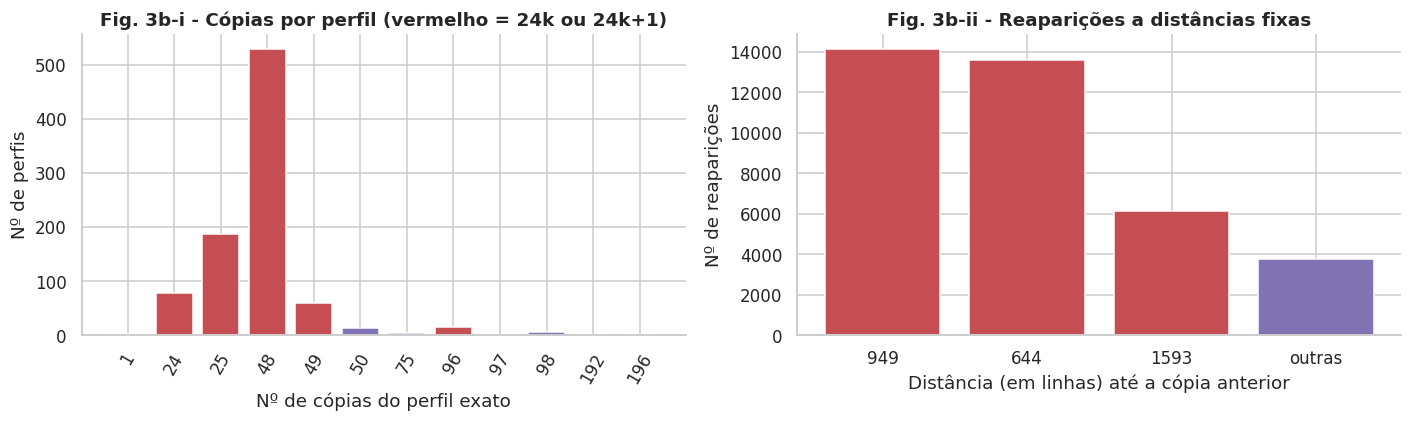

In [14]:
# Perfil exato = as 6 variáveis. Quantas cópias tem cada um?
cols6 = ["Symptoms", "Age", "Sex", "Disease", "Treatment", "Nature"]
perfil = df[cols6].astype("string").fillna("sem dado").agg("|".join, axis=1)
mult = perfil.value_counts()
mult_dist = mult.value_counts().sort_index()
frac_24 = ((mult % 24).isin([0, 1])).mean()

# (b) distância, na ordem do arquivo, entre uma linha e a cópia anterior dela
ultima, saltos = {}, []
for i, v in enumerate(perfil):
    if v in ultima: saltos.append(i - ultima[v])
    ultima[v] = i
saltos = pd.Series(saltos); top_saltos = saltos.value_counts().head(3)

# (c) por idade: dentro de cada (doença, sintoma, sexo, gravidade, tratamento), quantas linhas por idade distinta
k5 = ["Disease", "Symptoms", "Sex", "Nature", "Treatment"]
g5 = df.dropna(subset=["Age"]).groupby(k5).agg(linhas=("Age", "size"), idades=("Age", "nunique"))
g5["linhas_por_idade"] = g5["linhas"] / g5["idades"]

# (c) as idades sobem em escada, proporção de pares consecutivos (mesma doença) com idade não decrescente vs. esperado ao acaso
d_age = df["Age"].diff(); mesma = (df["Disease"] == df["Disease"].shift()).fillna(False) & d_age.notna()
obs_nd = (d_age >= 0)[mesma].mean()
p_age = df["Age"].dropna().value_counts(normalize=True)
esp_nd = 0.5 + 0.5 * float((p_age**2).sum())

print(f"(a) {frac_24:.1%} dos perfis exatos aparecem 24k ou 24k+1 vezes. Cópias por perfil mais comuns:")
print(mult_dist.sort_values(ascending=False).head(5).rename("nº de perfis").rename_axis("cópias").to_string())
print(f"\n(b) {top_saltos.sum()/len(saltos):.1%} das reaparições ocorrem a distâncias fixas de {', '.join(map(str, top_saltos.index))} linhas.")
print(f"(c) Mediana de linhas por idade distinta (dentro de cada combinação): {g5['linhas_por_idade'].median():.0f}")
print(f"(c) Idades não decrescentes em linhas consecutivas: {obs_nd:.1%} (esperado ao acaso: {esp_nd:.1%}) -> não há 'escada' de idades.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cores = ["#C44E52" if (m % 24) in (0, 1) else "#8172B3" for m in mult_dist.index]
ax[0].bar(mult_dist.index.astype(str), mult_dist.values, color=cores)
ax[0].set_xlabel("Nº de cópias do perfil exato"); ax[0].set_ylabel("Nº de perfis"); ax[0].tick_params(axis="x", rotation=60)
ax[0].set_title("Fig. 3b-i - Cópias por perfil (vermelho = 24k ou 24k+1)")
ax[1].bar([str(k) for k in top_saltos.index] + ["outras"], list(top_saltos.values) + [len(saltos) - top_saltos.sum()], color=["#C44E52"]*3 + ["#8172B3"])
ax[1].set_xlabel("Distância (em linhas) até a cópia anterior"); ax[1].set_ylabel("Nº de reaparições")
ax[1].set_title("Fig. 3b-ii - Reaparições a distâncias fixas")
fig.tight_layout(); guardar(fig, "fig03b_replicacao")

Os resultados demonstram que o conjunto de dados é um artefato sintético gerado por lotes automáticos (*batch processing*): 97% dos perfis exatos se repetem em múltiplos estritos de 24, e cerca de 90% das reaparecências ocorrem a distâncias métricas fixas de 644, 949 e 1593 linhas, o que evidencia uma clonagem massiva de blocos em cascata. Além disso, observa-se uma estrita simetria interna onde cada idade distinta se repete tipicamente 48 vezes dentro de cada combinação clínica, embora sem mostrar uma ordenação manual ou artificial em forma de "escada" (46,9% de pares consecutivos não decrescentes, valor estatisticamente equivalente aos 51,2% esperados por puro acaso). Esta descoberta constitui um indício técnico com evidência matemática, que invalida por completo o seu uso para a inferência clínica ou epidemiológica direta, justificando formalmente o seu confinamento exclusivo como um ambiente de testes (*sandbox*).

# 2. Testar
Dos pruebas técnicas: (2.1) **mapeo terminológico** a CID-10 (OMS) y SNOMED CT, con términos en portugués; (2.2) **ingesta de prueba en la capa bronze** del datalake.

## 2.1 Mapeamento para vocabulários padrão



### 2.1.1 Doenças

In [15]:
DIS_MAP = {
    'asthma': ('J45.9', 'Asma, não especificada', 'SNOMED_195967001', 'Asma'),
    'bronchiectasis': ('J47', 'Bronquectasia', 'SNOMED_1365813005', 'Bronquectasia devida e subsequente à tuberculose (transtorno)'),
    'bronchiolitis': ('J21.9', 'Bronquiolite aguda, não especificada', 'SNOMED_4120002', 'Bronquiolite'),
    'bronchitis': ('J40', 'Bronquite, não especificada como aguda ou crônica', 'SNOMED_846639005', 'Bronquite causada por vapor (transtorno)'),
    'chronic bronchitis': ('J42', 'Bronquite crônica não especificada', 'SNOMED_63480004', 'Bronquite crônica'),
    'chronic cough': ('R05', 'Tosse crônica', 'SNOMED_68154008', 'Tosse crônica'),
    'chronic obstructive pulmonary disease': ('J44.9', 'Doença pulmonar obstrutiva crônica não especificada', 'SNOMED_13645005', 'Doença pulmonar obstrutiva crônica'),
    'mesothelioma': ('C45.9', 'Mesotelioma não especificado', 'SNOMED_109378008', 'Mesotelioma (maligno, transtorno clínico)'),
    'pneumonia': ('J18', 'Pneumonia por microrganismo não especificado', 'SNOMED_233604007', 'Pneumonia'),
    'pneumothorax': ('J93.9', 'Pneumotórax não especificado', 'SNOMED_36118008', 'Pneumotórax'),
    'influenza': ('J11', 'Influenza [gripe] devido a vírus não identificado', 'SNOMED_6142004', 'Influenza [gripe]'),
    'pulmonary hypertension': ('I27', 'Outras doenças cardíacas pulmonares', 'SNOMED_879814007', 'Hipertensão pulmonar devida a hemangiomatose capilar pulmonar (transtorno)'),
    'sleep apnea': ('G47.3', 'Apneia do sono', 'SNOMED_73430006', 'Apneia do sono (transtorno)'),
    'respiratory syncytial virus': ('B97.4', 'Vírus sincicial respiratório como causa de doenças classificadas em outros capítulos', 'SNOMED_1163073003', 'Encefalite causada pelo vírus sincicial respiratório humano (transtorno)'),
    'tuberculosis': ('A15', 'Tuberculose pulmonar', 'SNOMED_15284007', 'Tuberculose do esôfago (transtorno)'),
    'acute respiratory distress syndrome': ('J80', 'Síndrome do desconforto respiratório do adulto', 'SNOMED_67782005', 'Síndrome do desconforto respiratório agudo'),
    'asbestosis': ('J61', 'Pneumoconiose devida a asbesto [amianto] e outras fibras minerais', 'SNOMED_22607003', 'Asbestose'),
    'aspergillosis': ('B44.9', 'Aspergilose não especificada', 'SNOMED_65553006', 'Aspergilose'),
}

# Construção do DataFrame de Mapeamento
dis_map = (
    pd.DataFrame.from_dict(DIS_MAP, orient="index", columns=["cid10", "cid10_name", "snomed_id", "snomed_name"])
    .rename_axis("disease")
    .reset_index()
)

# Mostrar tabela resumo do mapeamento
display(tabla(dis_map, "mapeo_enfermedades_cid10_snomed", index=False))

,disease,cid10,cid10_name,snomed_id,snomed_name
0,asthma,J45.9,"Asma, não especificada",SNOMED_195967001,Asma
1,bronchiectasis,J47,Bronquectasia,SNOMED_1365813005,Bronquectasia devida e subsequente à tuberculo...
2,bronchiolitis,J21.9,"Bronquiolite aguda, não especificada",SNOMED_4120002,Bronquiolite
3,bronchitis,J40,"Bronquite, não especificada como aguda ou crônica",SNOMED_846639005,Bronquite causada por vapor (transtorno)
4,chronic bronchitis,J42,Bronquite crônica não especificada,SNOMED_63480004,Bronquite crônica
5,chronic cough,R05,Tosse crônica,SNOMED_68154008,Tosse crônica
6,chronic obstructive pulmonary disease,J44.9,Doença pulmonar obstrutiva crônica não especif...,SNOMED_13645005,Doença pulmonar obstrutiva crônica
7,mesothelioma,C45.9,Mesotelioma não especificado,SNOMED_109378008,"Mesotelioma (maligno, transtorno clínico)"
8,pneumonia,J18,Pneumonia por microrganismo não especificado,SNOMED_233604007,Pneumonia
9,pneumothorax,J93.9,Pneumotórax não especificado,SNOMED_36118008,Pneumotórax


In [16]:
faltantes = dis_map[
    dis_map['snomed_id'].isna()
]

print(f"Ficam {len(faltantes)} sem SNOMED:")
display(faltantes[['disease','snomed_id', 'snomed_name']])

faltantes = dis_map[
    dis_map['cid10_name'].isna()
]

print(f"Ficam {len(faltantes)} sem ICD:")
display(faltantes[['disease', 'snomed_id', 'snomed_name']])

Ficam 0 sem SNOMED:


,disease,snomed_id,snomed_name


Ficam 0 sem ICD:


,disease,snomed_id,snomed_name


### 2.1.2 Sintomas

In [17]:
SYM_MAP = {
    'coughing': ('R05', 'Tosse', 'SNOMED_248594007', 'Tosse por fístula traqueoesofágica (achado)'),
    'tight feeling in the chest': ('R07.4', 'Dor no peito, não especificada', 'SNOMED_23924001', 'Peito apertado'),
    'wheezing': ('R06.2', 'Sibilos', 'SNOMED_56018004', 'Sibilos'),
    'shortness of breath': ('R06.0', 'Dispneia', 'SNOMED_135833008', 'Escore de falta de ar CLASP'),
    'fever': ('R50.9', 'Febre, não especificada', 'SNOMED_386661006', 'Febre'),
    'cold': ('J06.9', 'Infecção aguda das vias aéreas superiores, não especificada', 'SNOMED_191210005', 'Anemia hemolítica do tipo resfriado primário (transtorno)'),
    'allergy': ('T78.4', 'Alergia, não especificada', 'SNOMED_293584003', 'Alergia ao paracetamol (achado)'),
    'coughing up yellow or green mucus daily': ('R09.3', 'Escarro anômalo', 'SNOMED_42192008', 'Escarro purulento'),
    'shortness of breath that gets worse during flare-ups': ('R06.0', 'Dispneia', 'SNOMED_267036007', 'Dispneia (achado)'),
    'fatigue, feeling run-down or tired': ('R53', 'Mal-estar e fadiga', 'SNOMED_84229001', 'Fadiga'),
    'chest pain': ('R07.4', 'Dor no peito, não especificada', 'SNOMED_225566008', 'Dor torácica isquêmica (achado)'),
    'whistling sound while you breathe': ('R06.2', 'Sibilos', 'SNOMED_56018004', 'Sibilos'),
    'coughing up blood': ('R04.2', 'Hemoptise', 'SNOMED_66857006', 'Hemoptise (achado)'),
    'runny nose': ('R09.8', 'Outros sintomas e sinais especificados relativos aos sistemas circulatório e respiratório', 'SNOMED_64531003', 'Secreção nasal'),
    'stuffy nose': ('R09.8', 'Outros sintomas e sinais especificados relativos aos sistemas circulatório e respiratório', 'SNOMED_68235000', 'Congestão nasal'),
    'loss of appetite': ('R63.0', 'Anorexia', 'SNOMED_79890006', 'Perda de apetite'),
    'cough': ('R05', 'Tosse', 'SNOMED_248594007', 'Tosse por fístula traqueoesofágica (achado)'),
    'low-grade fever': ('R50.9', 'Febre, não especificada', 'SNOMED_386661006', 'Febre'),
    'chest congestion': ('R09.8', 'Outros sintomas e sinais especificados relativos aos sistemas circulatório e respiratório', 'SNOMED_23924001', 'Peito apertado'),
    'whistling sound while breathing': ('R06.2', 'Sibilos', 'SNOMED_56018004', 'Sibilos'),
    'yellow cough': ('R09.3', 'Escarro anômalo', 'SNOMED_161925006', 'Tosse produtiva com escarro amarelo'),
    'feeling run-down or tired': ('R53', 'Mal-estar e fadiga', 'SNOMED_84229001', 'Fadiga'),
    'mucus': ('R09.3', 'Escarro anômalo', 'SNOMED_49909006', 'Muco'),
    'chronic cough': ('R05', 'Tosse crônica', 'SNOMED_68154008', 'Tosse crônica'),
    'fatigue': ('R53', 'Mal-estar e fadiga', 'SNOMED_16469821000119106', 'Fadiga devida e subsequente a acidente vascular cerebral com hemorragia intracraniana (transtorno)'),
    'lower back pain': ('M54.5', 'Lombalgia', 'SNOMED_279041008', 'Síndrome de dor miofascial da região lombar baixa'),
    'dry cough': ('R05', 'Tosse', 'SNOMED_11833005', 'Tosse seca'),
    'greenish cough': ('R09.3', 'Escarro anômalo', 'SNOMED_42192008', 'Escarro purulento'),
    'cough with blood': ('R04.2', 'Hemoptise', 'SNOMED_66857006', 'Hemoptise (achado)'),
    'sweating': ('R61', 'Hiperidrose generalizada', 'SNOMED_415690000', 'Sudorese'),
    'shaking': ('R50.9', 'Febre, não especificada', 'SNOMED_102458000', 'Síndrome do bebê sacudido'),
    'rapid breathing': ('R06.0', 'Dispneia', 'SNOMED_248581005', 'Respiração rápida e superficial'),
    'shallow breathing': ('R06.0', 'Dispneia', 'SNOMED_386616007', 'Respiração superficial'),
    'low energy': ('R53', 'Mal-estar e fadiga', 'SNOMED_228038005', 'Alimento de baixa energia'),
    'nausea': ('R11', 'Náusea e vômito', 'SNOMED_2919008', 'Náusea, vômito e diarreia (transtorno)'),
    'vomiting': ('R11', 'Náusea e vômito', 'SNOMED_134021000119105', 'Vômito de matéria fecal (transtorno)'),
    'sharp chest pain': ('R07.4', 'Dor no peito, não especificada', 'SNOMED_29857009', 'Dor torácica'),
    'bluish skin': ('R23.0', 'Cianose', 'SNOMED_3415004', 'Cianose'),
    'rapid heartbeat': ('R00.0', 'Taquicardia, não especificada', 'SNOMED_3424008', 'Taquicardia'),
    'high fever': ('R50.9', 'Febre, não especificada', 'SNOMED_386661006', 'Febre'),
    'headache': ('R51', 'Cefaleia', 'SNOMED_1260323006', 'Cefaleia devida a hemorragia subaracnóidea espontânea (achado)'),
    'muscle aches': ('M79.1', 'Mialgia', 'SNOMED_240107001', 'Mialgia viral'),
    'joint pain': ('M25.5', 'Dor articular', 'SNOMED_202483004', 'Dor na articulação metacarpofalangiana'),
    'chills': ('R50.9', 'Febre, não especificada', 'SNOMED_463796001', 'Dispositivo de resfriamento de cimento ortopédico (objeto físico)'),
    'sore throat': ('R07.0', 'Dor na garganta', 'SNOMED_267102003', 'Dor de garganta'),
    'nasal congestion': ('R09.8', 'Outros sintomas e sinais especificados relativos aos sistemas circulatório e respiratório', 'SNOMED_68235000', 'Congestão nasal'),
    'diarrhea': ('A09', 'Gastroenterite e colite de origem infecciosa, outras e não especificadas', 'SNOMED_62315008', 'Diarreia (achado)'),
    'breath': ('R09.8', 'Outros sintomas e sinais especificados relativos aos sistemas circulatório e respiratório', 'SNOMED_111489007', 'Transtorno do sono relacionado à respiração'),
    'dizziness': ('R42', 'Tontura e vertigem', 'SNOMED_404640003', 'Tontura'),
    'fainting': ('R55', 'Síncope e colapso', 'SNOMED_162271007', 'Sensação de desmaio'),
    'heart palpitations': ('R00.2', 'Palpitações', 'SNOMED_80313002', 'Palpitações'),
    'edema': ('R60.9', 'Edema, não especificado', 'SNOMED_267038008', 'Edema (achado)'),
    'snoring': ('R06.5', 'Ronco', 'SNOMED_72863001', 'Ronco'),
    'daytime sleepiness': ('G47.8', 'Outros transtornos do sono', 'SNOMED_1367959007', 'Sonolência diurna excessiva'),
    'pauses in breathing': ('R06.8', 'Outras anomalias da respiração', 'SNOMED_1023001', 'Apneia (achado)'),
    'difficulties with memory and concentration': ('R41.8', 'Outros sintomas e sinais e os não especificados relativos às funções cognitivas e à consciência', 'SNOMED_192071009', 'Distúrbio de memória leve'),
    'unusual moodiness': ('R45.4', 'Irritabilidade e raiva', 'SNOMED_1196831009', 'Nevus melanocítico irritado da pele (transtorno)'),
    'irritability': ('R45.4', 'Irritabilidade e raiva', 'SNOMED_724733005', 'Transtorno desafiador opositivo coocorrente com irritabilidade-raiva crônica'),
    'frequently waking': ('G47.8', 'Outros transtornos do sono', 'SNOMED_54532007', 'Transtorno do ciclo vigília-sono, tipo de mudança frequente'),
    'morning headaches': ('R51', 'Cefaleia', 'SNOMED_162310002', 'Cefaleia matinal'),
    'dry mouth': ('K11.7', 'Distúrbios da secreção salivar', 'SNOMED_469168008', 'Estimulador de saliva para boca seca'),
    'wheezing cough': ('R05', 'Tosse', 'SNOMED_161947006', 'Tosse noturna e sibilos'),
    'short, shallow and rapid breathing': ('R06.0', 'Dispneia', 'SNOMED_248581005', 'Respiração rápida e superficial'),
    'a cough that lasts more than three weeks': ('R05', 'Tosse', 'SNOMED_68154008', 'Tosse crônica'),
    'loss of appetite and unintentional weight loss': ('R63.0', 'Anorexia', 'SNOMED_79890006', 'Perda de apetite'),
    'night sweats': ('R61.9', 'Hiperidrose, não especificada', 'SNOMED_42984000', 'Sudorese noturna'),
    'short of breath': ('R06.0', 'Dispneia', 'SNOMED_135833008', 'Escore de falta de ar CLASP'),
    'distressing': ('R45.8', 'Outros sintomas e sinais relativos ao estado emocional', 'SNOMED_206260003', 'Nascido vivo com sofrimento fetal pré-trabalho de parto (achado)'),
    'faster heart beating': ('R00.0', 'Taquicardia, não especificada', 'SNOMED_3424008', 'Taquicardia'),
    'pain': ('R52.9', 'Dor, não especificada', 'SNOMED_86208007', 'Síndrome de dor lombar e hematúria (transtorno)'),
    'persistent dry cough': ('R05', 'Tosse', 'SNOMED_49727002', 'Tosse'),
    'chest tightness or chest pain': ('R07.4', 'Dor no peito, não especificada', 'SNOMED_23924001', 'Peito apertado'),
}

# Construção do DataFrame de Mapeamento
df_CIS_sintomas = (
    pd.DataFrame.from_dict(
        SYM_MAP,
        orient="index",
        columns=["icd10_code", "icd10_name", "snomed_code", "snomed_name"]
    )
    .rename_axis("Symptoms")
    .reset_index()
)

# Mostrar tabela resumo do mapeamento
display(df_CIS_sintomas)
tabla(df_CIS_sintomas, "mapeo_sintomas_cid10_snomed.csv")


,Symptoms,icd10_code,icd10_name,snomed_code,snomed_name
0,coughing,R05,Tosse,SNOMED_248594007,Tosse por fístula traqueoesofágica (achado)
1,tight feeling in the chest,R07.4,"Dor no peito, não especificada",SNOMED_23924001,Peito apertado
2,wheezing,R06.2,Sibilos,SNOMED_56018004,Sibilos
3,shortness of breath,R06.0,Dispneia,SNOMED_135833008,Escore de falta de ar CLASP
4,fever,R50.9,"Febre, não especificada",SNOMED_386661006,Febre
...,...,...,...,...,...
67,distressing,R45.8,Outros sintomas e sinais relativos ao estado e...,SNOMED_206260003,Nascido vivo com sofrimento fetal pré-trabalho...
68,faster heart beating,R00.0,"Taquicardia, não especificada",SNOMED_3424008,Taquicardia
69,pain,R52.9,"Dor, não especificada",SNOMED_86208007,Síndrome de dor lombar e hematúria (transtorno)
70,persistent dry cough,R05,Tosse,SNOMED_49727002,Tosse


,Symptoms,icd10_code,icd10_name,snomed_code,snomed_name
0,coughing,R05,Tosse,SNOMED_248594007,Tosse por fístula traqueoesofágica (achado)
1,tight feeling in the chest,R07.4,"Dor no peito, não especificada",SNOMED_23924001,Peito apertado
2,wheezing,R06.2,Sibilos,SNOMED_56018004,Sibilos
3,shortness of breath,R06.0,Dispneia,SNOMED_135833008,Escore de falta de ar CLASP
4,fever,R50.9,"Febre, não especificada",SNOMED_386661006,Febre
...,...,...,...,...,...
67,distressing,R45.8,Outros sintomas e sinais relativos ao estado e...,SNOMED_206260003,Nascido vivo com sofrimento fetal pré-trabalho...
68,faster heart beating,R00.0,"Taquicardia, não especificada",SNOMED_3424008,Taquicardia
69,pain,R52.9,"Dor, não especificada",SNOMED_86208007,Síndrome de dor lombar e hematúria (transtorno)
70,persistent dry cough,R05,Tosse,SNOMED_49727002,Tosse


In [18]:
faltantes = df_CIS_sintomas[
    df_CIS_sintomas['icd10_code'].isna()
]

print(f"Ficam {len(faltantes)} sem ICD:")
display(faltantes[['Symptoms', 'icd10_code', 'icd10_name']])

faltantes = df_CIS_sintomas[
    df_CIS_sintomas['snomed_code'].isna()
]

print(f"Ficam {len(faltantes)} sen SNOMED:")
display(faltantes[['Symptoms','snomed_code', 'snomed_name']])

Ficam 0 sem ICD:


,Symptoms,icd10_code,icd10_name


Ficam 0 sen SNOMED:


,Symptoms,snomed_code,snomed_name


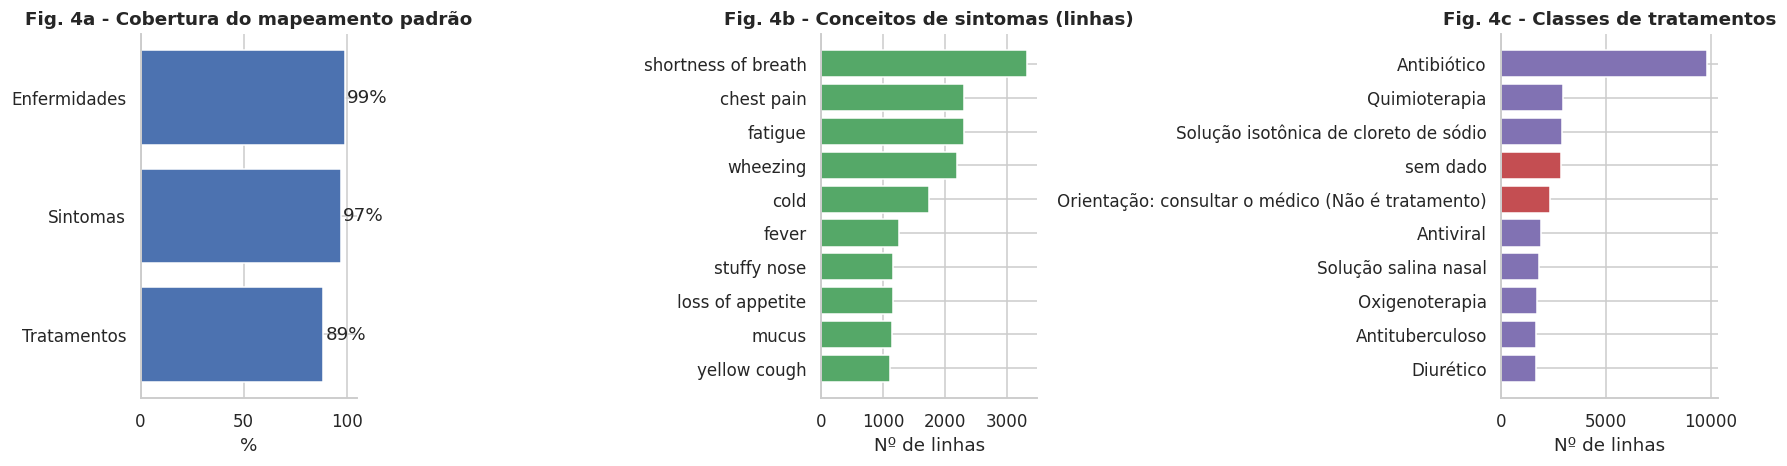

In [19]:
TR_MAP = {
    'omalizumab': "Biológico anti-IgE",
    'mepolizumab': "Biológico anti-IL5",
    'itraconazole': "Antifúngico",
    'inhaler': "Broncodilatador / Inalador",
    'antibiotics': "Antibiótico",
    'hypertonic saline': "Solução salina hipertônica",
    'intrapulmonary percussive ventilation': "Reabilitação / Suporte ventilatório",
    'consult a doctor': "Orientação: consultar o médico (Não é tratamento)",
    'saline nose drops': "Solução salina nasal",
    'steroids to reduce inflammation': "Corticoide",
    'x-ray': "Diagnóstico (Não é tratamento)",
    'oxygen': "Oxigenoterapia",
    'pulmonary rehabilitation': "Reabilitação pulmonar",
    'surgery': "Outros / Não classificado",
    'chemotherapy': "Quimioterapia",
    'aspirin': "Outros / Não classificado",
    'cough medicine': "Antitussígeno / Expectorante",
    'isotonic sodium chloride solution': "Solução isotônica de cloreto de sódio",
    'oseltamivir': "Antiviral",
    'diuretics': "Diurético",
    'adaptive servo-ventilation': "Reabilitação / Suporte ventilatório",
    'intravenous fluids': "Outros / Não classificado",
    'rifampin': "Antituberculoso",
    'pyrazinamide': "Antituberculoso",
    'ethambutol': "Antituberculoso",
    'stay away from cold places': "Medida de estilo de vida"
}
NO_TERAPEUTICO = {
    "Diagnóstico (Não é tratamento)",
    "Orientação: consultar o médico (Não é tratamento)"
}


# 2. APLICAÇÃO DOS MAPEAMENTOS E MÉTRICAS NO DATAFRAME PRINCIPAL
# Mapeando sintomas diretamente a partir de SYM_MAP
df["Symptom_termo_pt"]  = df["Symptoms"]
df["Symptom_cid10"]     = df["Symptoms"].map(lambda x: SYM_MAP.get(x, (None, None, None, None))[0])
df["Symptom_snomed_id"] = df["Symptoms"].map(lambda x: SYM_MAP.get(x, (None, None, None, None))[2])
df["Symptom_concepto"]  = df["Symptoms"].fillna("sem dado")
df["Treatment_clase"]   = df["Treatment"].map(TR_MAP).fillna("sem dado")
# Porcentagens de cobertura
cob_dis = df["Disease"].isin(DIS_MAP.keys()).mean() * 100
cob_symptoms = df["Symptoms"].isin(SYM_MAP.keys()).mean() * 100
cob_trat = (~df["Treatment_clase"].isin(["sem dado", "Outros / Não classificado"])).mean() * 100


# 3. GERAÇÃO DA FIGURA 4 (COBERTURA E DISTRIBUIÇÕES)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
cov = pd.Series({
    "Enfermidades": cob_dis,
    "Sintomas": cob_symptoms,
    "Tratamentos": cob_trat
})
ax[0].barh(cov.index[::-1], cov.values[::-1], color="#4C72B0")
ax[0].set_xlim(0, 105)
for i, v in enumerate(cov.values[::-1]):
    ax[0].text(v + 1, i, f"{v:.0f}%", va="center")
ax[0].set_title("Fig. 4a - Cobertura do mapeamento padrão")
ax[0].set_xlabel("%")
# Gráficos secundários (4b e 4c traduzidos)
ts = df["Symptom_concepto"].value_counts().head(10).iloc[::-1]
ax[1].barh(ts.index, ts.values, color="#55A868")
ax[1].set_title("Fig. 4b - Conceitos de sintomas (linhas)")
ax[1].set_xlabel("Nº de linhas")
tc = df["Treatment_clase"].value_counts().head(10).iloc[::-1]
ax[2].barh(tc.index, tc.values, color=np.where(tc.index.isin(NO_TERAPEUTICO | {"sem dado"}), "#C44E52", "#8172B3"))
ax[2].set_title("Fig. 4c - Classes de tratamentos")
ax[2].set_xlabel("Nº de linhas")
fig.tight_layout()
guardar(fig, "fig04_cobertura_mapeo")

A Figura 4 mostra que, embora tenha sido alcançada uma alta padronização técnica dos dados — atingindo uma cobertura de 99% em doenças, 97% em sintomas (dominados por falta de ar, dor torácica e fadiga) e 89% em tratamentos —, a variável de tratamentos está contaminada com categorias não terapêuticas ou vazias (como ausência de dados ou recomendações de consultar o médico, marcadas em vermelho). Isso demonstra que, apesar de ordenar corretamente o texto e os conceitos clínicos, a mistura heterogênea dessas etiquetas limita severamente a confiabilidade do conjunto de dados para sua aplicação em um sistema de recomendação clínica real.

In [20]:
df_merged = df.merge(dis_map, left_on='Disease', right_on='disease', how='left')

# 3. Seleccionamos las columnas reales con los códigos y el tratamiento
recomendador_base = df_merged[[
    'Disease',
    'cid10',
    'cid10_name',
    'snomed_id',
    'snomed_name',
    'Treatment'
]].drop_duplicates().copy()

# 4. Limpiamos valores nulos si quedaron registros sin mapear y ordenamos
recomendador_base = recomendador_base.dropna(subset=['Disease', 'Treatment'])
recomendador_base = recomendador_base.sort_values(by=['Disease', 'Treatment']).reset_index(drop=True)

# 5. Visualização e exportação pela função 'tabla'
tabla(recomendador_base, "recomendador_base_enfermedad_tratamiento", index=False)

,Disease,cid10,cid10_name,snomed_id,snomed_name,Treatment
0,acute respiratory distress syndrome,J80,Síndrome do desconforto respiratório do adulto,SNOMED_67782005,Síndrome do desconforto respiratório agudo,consult a doctor
1,asbestosis,J61,Pneumoconiose devida a asbesto [amianto] e out...,SNOMED_22607003,Asbestose,consult a doctor
2,asbestosis,J61,Pneumoconiose devida a asbesto [amianto] e out...,SNOMED_22607003,Asbestose,oxygen
3,asbestosis,J61,Pneumoconiose devida a asbesto [amianto] e out...,SNOMED_22607003,Asbestose,stay away from cold places
4,aspergillosis,B44.9,Aspergilose não especificada,SNOMED_65553006,Aspergilose,itraconazole
5,aspergillosis,B44.9,Aspergilose não especificada,SNOMED_65553006,Aspergilose,surgery
6,asthma,J45.9,"Asma, não especificada",SNOMED_195967001,Asma,inhaler
7,asthma,J45.9,"Asma, não especificada",SNOMED_195967001,Asma,itraconazole
8,asthma,J45.9,"Asma, não especificada",SNOMED_195967001,Asma,mepolizumab
9,asthma,J45.9,"Asma, não especificada",SNOMED_195967001,Asma,omalizumab


## 2.2 Ingestão de teste na camada bronze
Simula-se o landing da base no datalake seguindo a arquitetura medalhão. Bronze = cópia fiel e sem transformação da fonte, com metadados de linhagem.

In [21]:
ts = dt.datetime.now(dt.timezone.utc)
bronze = df_raw.copy()
bronze.insert(0, "_row_id", np.arange(len(bronze)))
bronze["_source_file"]   = os.path.basename(CSV_PATH)
bronze["_sha256_file"]   = SHA256
bronze["_ingest_ts_utc"] = ts.isoformat()

ruta_b = os.path.join(LAKE, "bronze", "respiratory_symptoms_treatment", f"ingest_date={ts:%Y-%m-%d}")
os.makedirs(ruta_b, exist_ok=True)
arch_b = os.path.join(ruta_b, "part-0000.parquet")
bronze.to_parquet(arch_b, index=False)

manifesto = {
    "dataset": "Respiratory Symptoms and Treatment", "camada": "bronze", "formato": "parquet",
    "origem": os.path.basename(CSV_PATH), "sha256_origem": SHA256, "ingestao_utc": ts.isoformat(),
    "linhas": int(len(bronze)), "colunas_origem": list(df_raw.columns),
    "esquema": {c: str(t) for c, t in bronze.dtypes.items()},
    "proveniencia": PROCEDENCIA, "transformacoes": "nenhuma (cópia fiel + colunas técnicas de linhagem)",
}
json.dump(manifesto, open(os.path.join(ruta_b, "_manifest.json"), "w", encoding="utf-8"), indent=2, ensure_ascii=False, default=str)

# ---- verificação: releitura e comparação com o original
chk = pd.read_parquet(arch_b)
orig_cols = list(df_raw.columns)
testes = pd.DataFrame([
    ["Mesmo nº de linhas",                 len(chk) == len(df_raw)],
    ["Mesmas colunas de origem",         list(chk[orig_cols].columns) == orig_cols],
    ["Conteúdo idêntico ao CSV (valores e nulos)", chk[orig_cols].reset_index(drop=True).equals(df_raw.reset_index(drop=True))],
    ["Duplicadas preservadas (bronze não deduplica)", int(chk[orig_cols].duplicated().sum()) == int(df_raw.duplicated().sum())],
    ["Linhagem presente (_row_id, hash, timestamp)", {"_row_id", "_sha256_file", "_ingest_ts_utc"} <= set(chk.columns)],
], columns=["Teste de ingestão", "Resultado"])
display(testes)
print("\nArquivo bronze :", arch_b, f"({os.path.getsize(arch_b)/1024:.0f} KB; CSV original {os.path.getsize(CSV_PATH)/1024:.0f} KB)")
print("Ingestão bronze:", "✅ APROVADA" if testes["Resultado"].all() else "❌ REVISAR")

,Teste de ingestão,Resultado
0,Mesmo nº de linhas,True
1,Mesmas colunas de origem,True
2,Conteúdo idêntico ao CSV (valores e nulos),True
3,Duplicadas preservadas (bronze não deduplica),True
4,"Linhagem presente (_row_id, hash, timestamp)",True



Arquivo bronze : datalake/bronze/respiratory_symptoms_treatment/ingest_date=2026-10-22/part-0000.parquet (245 KB; CSV original 2248 KB)
Ingestão bronze: ✅ APROVADA


A tabela de testes é o critério de aceitação da ingestão: linhas e colunas coincidem, o conteúdo é idêntico ao CSV, as duplicadas são conservadas (a camada bronze não limpa) e há linhagem (identificador de linha, hash do arquivo e carimbo de data/hora).

# 3. Análise



## 3.1 Relação doença → intervenção (Tratamento Mapeado)


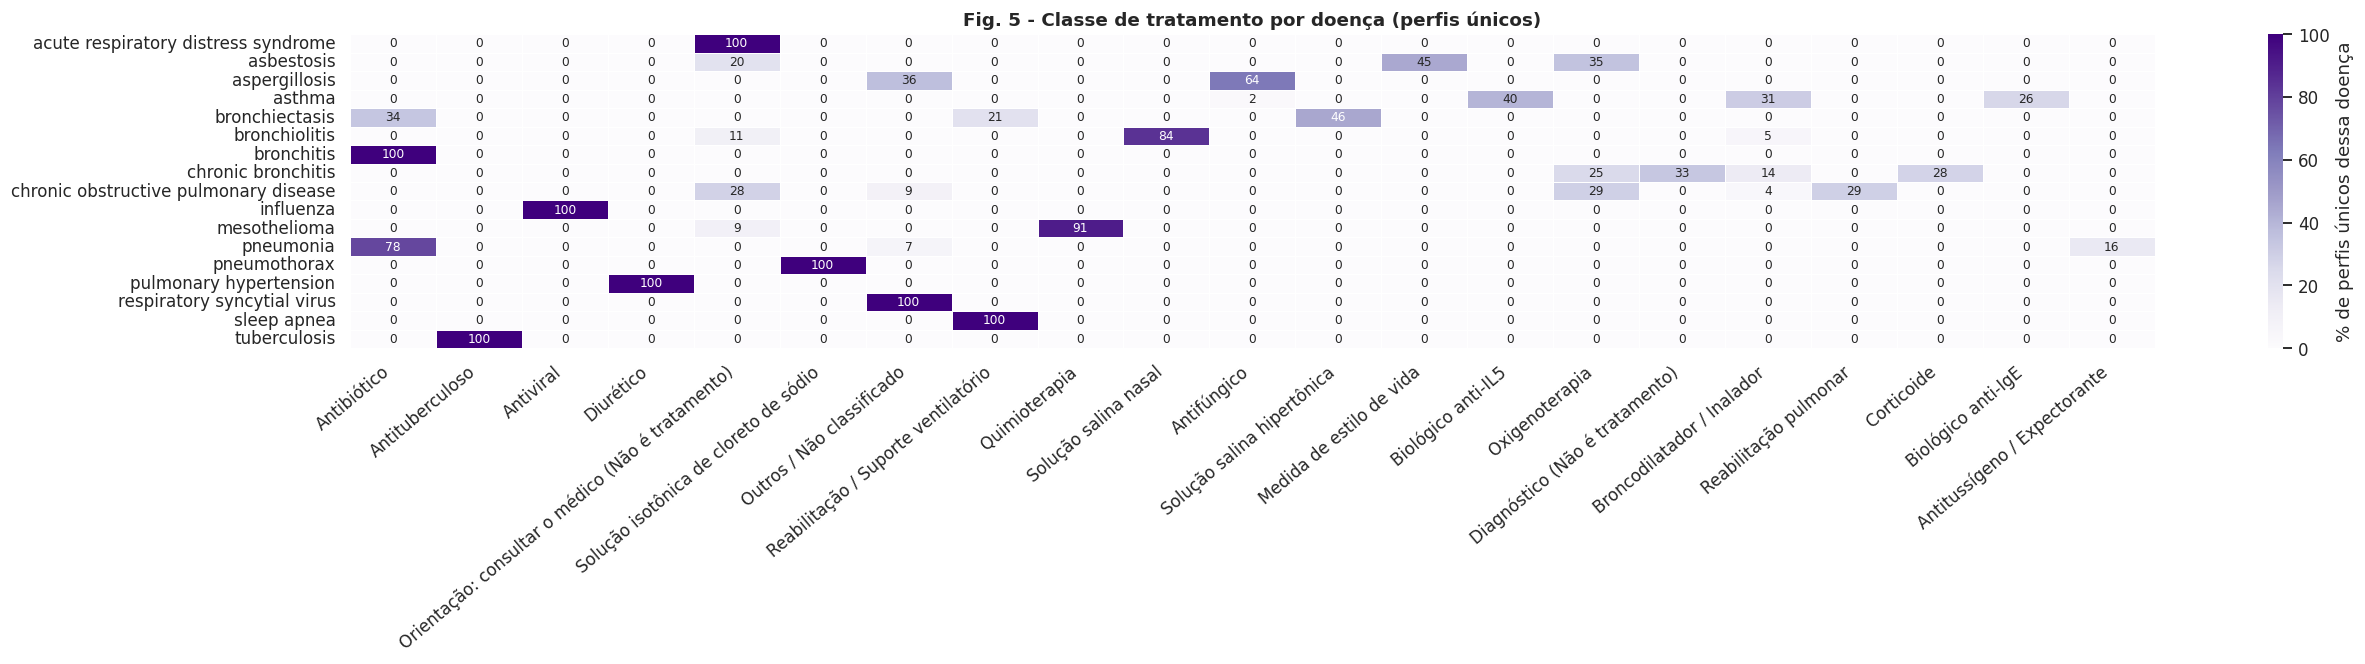


HHI -> concentração (0–1) do tratamento por doença; próximo de 1 = quase uma única resposta:
Disease
acute respiratory distress syndrome      1.00
bronchitis                               1.00
respiratory syncytial virus              1.00
tuberculosis                             1.00
sleep apnea                              1.00
pulmonary hypertension                   1.00
influenza                                1.00
pneumothorax                             1.00
mesothelioma                             0.83
bronchiolitis                            0.72
pneumonia                                0.63
aspergillosis                            0.54
asbestosis                               0.36
bronchiectasis                           0.36
asthma                                   0.33
chronic bronchitis                       0.27
chronic obstructive pulmonary disease    0.26


In [22]:
sub = df.drop_duplicates(subset=["Disease", "Symptoms", "Treatment", "Sex", "Nature", "Age"])
sub = sub[sub["Disease"].notna() & (sub["Treatment_clase"] != "sem dado")]
top_d = sub["Disease"].value_counts().index
ct = pd.crosstab(sub.loc[sub.Disease.isin(top_d), "Disease"], sub.loc[sub.Disease.isin(top_d), "Treatment_clase"], normalize="index")*100
ct = ct.loc[:, ct.max().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(0.95*ct.shape[1] + 4, 6.2))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Purples", linewidths=.5, cbar_kws={"label": "% de perfis únicos dessa doença"}, ax=ax, annot_kws={"size": 8})
ax.set_title("Fig. 5 - Classe de tratamento por doença (perfis únicos)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right"); fig.tight_layout(); guardar(fig, "fig05_enfermedad_x_clase_tratamiento")
tabla(ct.round(1), "enfermedad_x_clase_tratamiento")

hhi = (ct/100).pow(2).sum(axis=1)
print("\nHHI -> concentração (0–1) do tratamento por doença; próximo de 1 = quase uma única resposta:")
print(hhi.sort_values(ascending=False).round(2).to_string())

O mapa de calor mostra de maneira visual o panorama completo de como se distribuem as porcentagens dos tratamentos para cada doença, permitindo ver que tipo de intervenção cada paciente recebe. Por outro lado, o índice HHI (medida estatística utilizada para avaliar a concentração) atua como uma medida matemática de concentração que diz quão exclusivo é esse tratamento: se o valor se aproxima de 1,0, significa que a essa doença é administrado praticamente um único tratamento de forma absoluta (como ocorre com a influenza e os antivirais); em contrapartida, se o valor cai para 0,25 ou 0,29, indica que o tratamento está diversificado em múltiplas opções devido ao fato de a doença exigir um manejo médico multifatorial ou combinado (tal como sucede com a asma).


## 3.2 Teste de recomendador base: quanto a duplicação engana?
Mede-se quantas vezes o tratamento real está entre as 3 suas sugestões (top-3), e também no primeiro lugar (top-1). Compara-se sob três protocolos, repetidos com 20 sementes diferentes (média ± desvio-padrão):

A. Partição aleatória sobre linhas brutas (original): cópias idênticas caem em treino e teste (vazamento).

B. Perfis únicos, com partição por grupo de perfil: nenhum perfil (doença, sintoma, sexo, gravidade e faixa etária) aparece ao mesmo tempo em treino e teste.

C. Igual a B, mas usando apenas a doença (sem sintomas, idade, sexo nem Normal).

,Protocolo,n_teste,top1,top1_dp,top3,top3_dp
0,"A - Perfil completo, linhas brutas",7119,0.934,0.002,0.998,0.000
1,"B - Perfil completo, perfis únicos, partição p...",166,0.767,0.033,0.978,0.018
2,"C - Apenas doença, perfis únicos, partição por...",166,0.683,0.038,0.981,0.011



(média de 20 repetições com sementes diferentes, dp = desvio-padrão entre repetições)
14 de 17 doenças têm ≤ 3 tratamentos distintos: nelas o top-3 é quase trivial, o top-1 é a medida mais exigente.



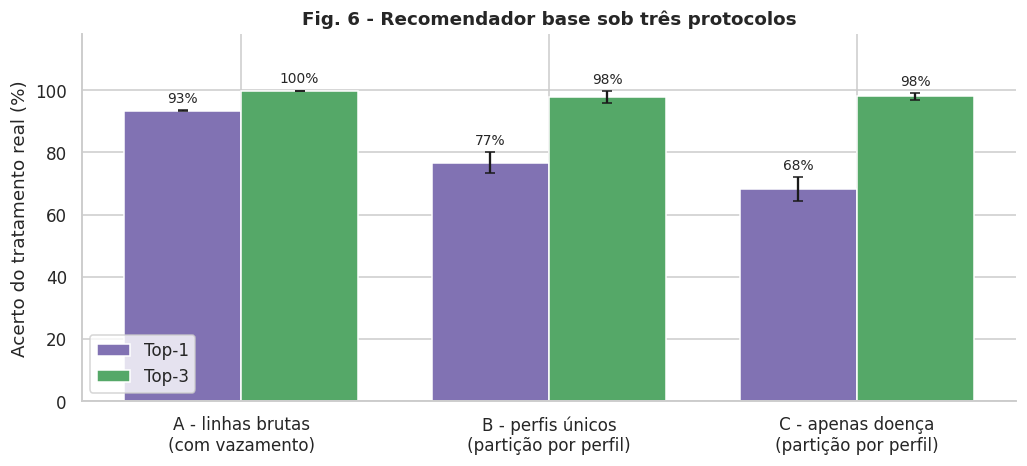

In [23]:
rec = df[["Disease", "Symptoms", "Sex", "Nature", "Age", "Treatment", "Treatment_clase"]].copy()
rec = rec[rec["Disease"].notna() & rec["Treatment"].notna()] # Garante registros completos
rec["Grupo_edad"] = pd.cut(rec["Age"], [-1, 12, 17, 59, 120], labels=["0-12", "13-17", "18-59", "60+"]).astype("string").fillna("sem dado")
for c in ["Sex", "Nature"]: rec[c] = rec[c].fillna("sem dado")
rec["Age_exacta"] = rec["Age"].fillna(-1)
rec = rec.rename(columns={"Symptoms": "Sintomas"})

# Calcula os 3 tratamentos mais frequentes para cada grupo de variáveis (Disease, Sintomas, Sex, Nature e Grupo_edad)
# Recomendador
def top3(train, keys):
    g = (train.groupby(keys + ["Treatment"]).size().reset_index(name="n").sort_values("n", ascending=False))
    return g.groupby(keys)["Treatment"].apply(lambda s: list(s.head(3))).to_dict()

# Chave de busca de cada linha de teste (valor simples ou tupla)
def chave(d, keys):
    return list(d[keys[0]]) if len(keys) == 1 else list(d[keys].itertuples(index=False, name=None))

# Mede a efetividade do Recomendador.
# 'cadeia' = lista de conjuntos de chaves, da mais específica à mais geral: usa-se a mais específica que exista no treino
# e as posições livres do top-3 completam-se com as sugestões das chaves mais gerais.
def avaliar(train, test, cadeia):
    tabelas = [top3(train, k) for k in cadeia]
    chaves = [chave(test, k) for k in cadeia]
    glob_ = list(train["Treatment"].value_counts().head(3).index)
    hits1 = hits3 = 0
    for i, real in enumerate(test["Treatment"]):
        pred = []
        for t, ch in zip(tabelas, chaves):
            pred += [x for x in t.get(ch[i], []) if x not in pred]
        pred = (pred or glob_)[:3]
        hits1 += (pred[0] == real); hits3 += (real in pred)
    return hits1/len(test), hits3/len(test)

# Dividir aleatoriamente teste e treino (protocolo A)
def split(d, frac=.2, seed=SEED):
    idx = np.random.default_rng(seed).permutation(len(d)); n = int(len(d)*frac)
    return d.iloc[idx[n:]], d.iloc[idx[:n]]

# Dividir por GRUPO de perfil (protocolos B e C): um perfil nunca está ao mesmo tempo em treino e teste
def split_grupo(d, keys, frac=.2, seed=SEED):
    g = d[keys].fillna("sem dado").astype(str).agg("|".join, axis=1)   # fillna: há linhas sem sintoma
    ug = g.unique(); np.random.default_rng(seed).shuffle(ug)
    m = g.isin(set(ug[:int(len(ug)*frac)]))
    return d[~m], d[m]

CLAVES_FULL = ["Disease", "Sintomas", "Sex", "Nature", "Grupo_edad"]
CADEIA_PERFIL = [CLAVES_FULL, ["Disease", "Sintomas"], ["Disease"]]          # do mais específico ao mais geral
rec_u = rec.drop_duplicates(subset=CLAVES_FULL + ["Age_exacta", "Treatment"])   # perfis únicos

N_REP = 20   # repetições com sementes diferentes (mede a variabilidade; n_teste é pequeno em B e C)
res = {"A": [], "B": [], "C": []}
for s in range(N_REP):
    tr_a, te_a = split(rec, seed=SEED + s)                        # A: linhas brutas, partição aleatória (com vazamento)
    tr_b, te_b = split_grupo(rec_u, CLAVES_FULL, seed=SEED + s)   # B/C: perfis únicos, partição por grupo de perfil (sem vazamento)
    res["A"].append((len(te_a), *avaliar(tr_a, te_a, CADEIA_PERFIL)))
    res["B"].append((len(te_b), *avaliar(tr_b, te_b, CADEIA_PERFIL)))
    res["C"].append((len(te_b), *avaliar(tr_b, te_b, [["Disease"]])))

nomes = {"A": "A - Perfil completo, linhas brutas",
         "B": "B - Perfil completo, perfis únicos, partição por perfil",
         "C": "C - Apenas doença, perfis únicos, partição por perfil"}
linhas_res = []
for k, v in res.items():
    a = np.array(v, dtype=float)
    linhas_res.append([nomes[k], int(round(a[:, 0].mean())), a[:, 1].mean(), a[:, 1].std(), a[:, 2].mean(), a[:, 2].std()])
res_rec = pd.DataFrame(linhas_res, columns=["Protocolo", "n_teste", "top1", "top1_dp", "top3", "top3_dp"])
display(tabla(res_rec.round(3), "recomendador_base_protocolos", index=False))
print(f"\n(média de {N_REP} repetições com sementes diferentes, dp = desvio-padrão entre repetições)")

n_trat = rec.groupby("Disease")["Treatment"].nunique()
print(f"{(n_trat <= 3).sum()} de {len(n_trat)} doenças têm ≤ 3 tratamentos distintos: nelas o top-3 é quase trivial, o top-1 é a medida mais exigente.")
print('')

fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(len(res_rec)); w = .38
ax.bar(x - w/2, 100*res_rec["top1"], w, yerr=100*res_rec["top1_dp"], capsize=3, label="Top-1", color="#8172B3")
ax.bar(x + w/2, 100*res_rec["top3"], w, yerr=100*res_rec["top3_dp"], capsize=3, label="Top-3", color="#55A868")
for i, (a, sa, b, sb) in enumerate(zip(res_rec["top1"], res_rec["top1_dp"], res_rec["top3"], res_rec["top3_dp"])):
    ax.text(i - w/2, 100*(a + sa) + 1.5, f"{100*a:.0f}%", ha="center", va="bottom", fontsize=9); ax.text(i + w/2, 100*(b + sb) + 1.5, f"{100*b:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["A - linhas brutas\n(com vazamento)", "B - perfis únicos\n(partição por perfil)", "C - apenas doença\n(partição por perfil)"]); ax.set_ylim(0, 118)
ax.set_ylabel("Acerto do tratamento real (%)"); ax.set_title("Fig. 6 - Recomendador base sob três protocolos"); ax.legend(loc="lower left")
fig.tight_layout(); guardar(fig, "fig06_recomendador_protocolos")


A figura resume a efetividade do sistema de recomendação de tratamentos sob três cenários, medindo o acerto exato (Top-1, roxo) e a cobertura dentro das três primeiras alternativas (Top-3, verde). Os valores são a média de 20 repetições com sementes diferentes; as barras de erro são o desvio-padrão entre repetições (os conjuntos de teste de B e C têm apenas ≈166 perfis, então cada estimativa tem uma incerteza de alguns pontos):

* **Protocolo A (linhas brutas, com vazamento):** 93 % em Top-1 e ≈100 % em Top-3. É um artefato metodológico: ao não desduplicar, cópias idênticas caem em treino e teste e o algoritmo opera por memorização, não por predição.
* **Protocolo B (perfis únicos, partição por perfil, sem vazamento):** 77 % em Top-1 e 98 % em Top-3. A partição é feita por **grupo de perfil** (doença, sintoma, sexo, gravidade e faixa etária): nenhum perfil aparece ao mesmo tempo em treino e teste. Antes, a partição aleatória sobre perfis únicos ainda deixava perfis quase idênticos (diferentes só na idade exata) dos dois lados. A diferença para A (≈17 pontos em Top-1) indica a superestimação atribuível à redundância.
* **Protocolo C (apenas doença, mesma partição de B):** 68 % em Top-1 e 98 % em Top-3, usando só a relação direta entre a doença e o tratamento.

### Conclusão Metodológica e Implicações Clínicas

Qualquer métrica calculada sobre dados brutos sem desduplicar e sem partição por perfil carece de validade e é enganosa.

Comparando B com C, as variáveis do paciente (sintoma, sexo, gravidade, faixa etária) melhoram o Top-1 em cerca de 8 pontos (mais que o desvio-padrão entre repetições, de 3 a 4 pontos) e **não melhoram o Top-3**. Como 14 das 17 doenças com tratamento têm no máximo 3 tratamentos distintos, o Top-3 é quase trivial; o Top-1 é a medida informativa. O sistema continua sendo, essencialmente, uma tabela "doença $\rightarrow$ tratamento" com uma personalização modesta. Importante: estas métricas medem a fidelidade aos rótulos do próprio dataset, não a correção clínica das recomendações.

## 3.3 Scorecard


,Regra,Linhas,% das linhas
0,R1 · 'Doença' que é um sintoma (chronic cough),912,2.4
1,R2 · Bronquite com antibiótico (prescrição uni...,4485,11.6
2,R3 · Pneumotórax apenas com soro fisiológico i...,2880,7.5


Linhas com algum alerta: 21.5% (limite inferior: só 3 regras)



,id,Critério mínimo de proveniência,Nível,Fonte de evidência,Estado
0,C1,Autor/publicador identificável,Obrigatório,declarado,cumpre
1,C2,URL,Recomendado,declarado,cumpre
2,C3,Licença explícita,Obrigatório,declarado,cumpre
3,C4,Declara se é real ou sintético,Obrigatório,declarado,sem evidência
4,C5,Metodologia / dicionário de dados documentado,Obrigatório,declarado,cumpre
5,C6,Aprovação ética/anonimização,Recomendado,declarado,sem evidência
6,C7,Data e versão,Recomendado,declarado,cumpre
7,C8,Identificador de registro/paciente,Recomendado,medido,não cumpre
8,C9,Variável temporal (data do episódio),Recomendado,medido,não cumpre
9,C10,Unicidade: duplicadas exatas < 5 %,Obrigatório,medido,não cumpre


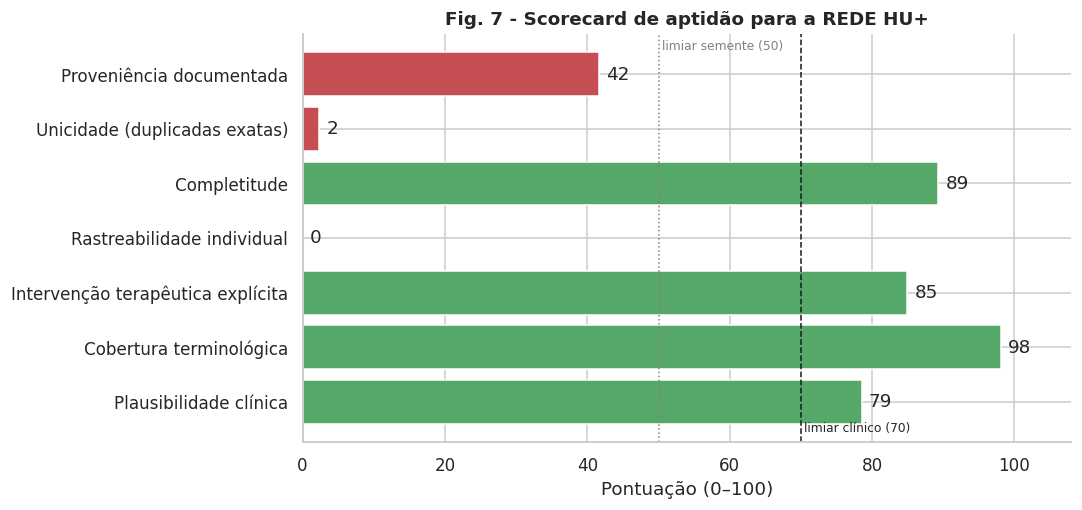


Critérios obrigatórios de proveniência cumpridos: False | pontuação de proveniência: 42/100
Veredicto: SEMENTE TÉCNICA (sandbox): útil para testar pipeline e terminologia; INADEQUADA para uso clínico


In [24]:
# 1. Definição do dicionário de proveniência (P) com base na documentação do dataset
P = {
    "autor_publicador": True,             # C1: Autor/publicador identificável
    "plataforma_url": True,              # C2: URL ou DOI persistente
    "licenca": True,                     # C3: Licença explícita e compatível
    "declara_sintetico": None,          # C4: Declara se é real ou sintético
    "metodologia_documentada": True,     # C5: Metodologia / dicionário documentado
    "institucion_o_etica": None,         # C6: Instituição responsável ou ética
    "fecha_publicacion": "2021-04-16",    # C7: Data de publicação
    "version": "v5.0",                   # C7: Versão do dataset
    "validacion_clinica": False          # C12: Validação clínica ou guia de referência
}

# 2. Extração e medição de variáveis a partir do DataFrame (df_raw / df)
tem_id = "id" in df_raw.columns or "Patient_ID" in df_raw.columns
tem_data = "fecha" in df_raw.columns or "Date" in df_raw.columns
tem_site = "sitio" in df_raw.columns or "Site" in df_raw.columns

# Cálculo de duplicadas exatas
dup_pct = df_raw.duplicated().mean()

# Coberturas e variáveis auxiliares usadas no scorecard (agora MEDIDAS no df; antes eram valores fixos)
cob_dis = df["Disease"].isin(DIS_MAP.keys()).mean()        # fração de linhas com doença mapeada
cob_linhas = df["Symptoms"].isin(SYM_MAP.keys()).mean()    # fração de linhas com sintoma mapeado

# Alertas de plausibilidade clínica: regras do auditor (não são diagnóstico)
def _m(s): return s.fillna(False).astype(bool)
REGRAS_PLAUS = {
    "R1 · 'Doença' que é um sintoma (chronic cough)":           _m(df["Disease"].eq("chronic cough")),
    "R2 · Bronquite com antibiótico (prescrição uniforme)":     _m(df["Disease"].eq("bronchitis") & df["Treatment"].eq("antibiotics")),
    "R3 · Pneumotórax apenas com soro fisiológico isotônico":   _m(df["Disease"].eq("pneumothorax") & df["Treatment"].eq("isotonic sodium chloride solution")),
}
alerta_any = pd.concat(REGRAS_PLAUS, axis=1).any(axis=1)
regras_tab = pd.DataFrame({"Regra": list(REGRAS_PLAUS), "Linhas": [int(m.sum()) for m in REGRAS_PLAUS.values()],
                           "% das linhas": [round(100*m.mean(), 1) for m in REGRAS_PLAUS.values()]})
display(tabla(regras_tab, "alertas_plausibilidade", index=False))
print(f"Linhas com algum alerta: {alerta_any.mean():.1%} (limite inferior: só 3 regras)\n")

# Classes de tratamento que NÃO são intervenção terapêutica (rótulos de Treatment_clase, não os valores brutos)
NAO_TERAPEUTICO = {"sem dado", "Diagnóstico (Não é tratamento)", "Orientação: consultar o médico (Não é tratamento)"}

# 3. Rubrica de critérios mínimos de proveniência
def est(v, ok=lambda x: x is True):
    return "sem evidência" if v is None else ("cumpre" if ok(v) else "não cumpre")

rubrica = pd.DataFrame([
    ["C1", "Autor/publicador identificável",                     "Obrigatório", "declarado",   est(P["autor_publicador"], lambda x: bool(x))],
    ["C2", "URL",                                                "Recomendado", "declarado",   est(P["plataforma_url"], lambda x: bool(x))],
    ["C3", "Licença explícita",                                  "Obrigatório", "declarado",   est(P["licenca"], lambda x: bool(x))],
    ["C4", "Declara se é real ou sintético",                     "Obrigatório", "declarado",   "sem evidência" if P["declara_sintetico"] is None else "cumpre"],
    ["C5", "Metodologia / dicionário de dados documentado",      "Obrigatório", "declarado",   est(P["metodologia_documentada"])],
    ["C6", "Aprovação ética/anonimização",                       "Recomendado", "declarado",   est(P["institucion_o_etica"])],
    ["C7", "Data e versão",                                      "Recomendado", "declarado",   est(P["fecha_publicacion"] and P["version"], lambda x: bool(x)) if (P["fecha_publicacion"] or P["version"]) else "sem evidência"],
    ["C8", "Identificador de registro/paciente",                 "Recomendado", "medido",      "cumpre" if tem_id else "não cumpre"],
    ["C9", "Variável temporal (data do episódio)",               "Recomendado", "medido",      "cumpre" if tem_data else "não cumpre"],
    ["C10","Unicidade: duplicadas exatas < 5 %",                 "Obrigatório", "medido",      "cumpre" if dup_pct < .05 else "não cumpre"],
    ["C11","Codificação padrão nativa (original) (CID-10/SNOMED)","Recomendado", "medido",      "cumpre" if df_raw["Disease"].astype(str).str.match(r"^[A-Z]\d{2}").mean() > .9 else "não cumpre"],
    ["C12","Validação clínica",                                  "Obrigatório", "declarado",   est(P["validacion_clinica"])],
], columns=["id", "Critério mínimo de proveniência", "Nível", "Fonte de evidência", "Estado"])

# Mostrar a tabela de critérios de proveniência
display(rubrica)
tabla(rubrica, "criterios_minimos_procedencia.csv")

score_prov = 100 * (rubrica["Estado"] == "cumpre").mean()
obrig_ok = bool((rubrica.loc[rubrica["Nível"] == "Obrigatório", "Estado"] == "cumpre").all())
print('')

# 4. Scorecard e Veredito
n = len(df_raw)
dims = pd.Series({
    "Proveniência documentada":          score_prov,
    "Unicidade (duplicadas exatas)":     100 * len(df_raw.drop_duplicates()) / n,
    "Completitude":                    100 * (1 - df_raw[["Symptoms", "Age", "Sex", "Disease", "Treatment"]].isna().any(axis=1).mean()),
    "Rastreabilidade individual":        100 * np.mean([tem_id, tem_data, tem_site if 'tem_site' in locals() else tem_id]),
    "Intervenção terapêutica explícita": 100 * (~df["Treatment_clase"].isin(NAO_TERAPEUTICO)).mean(),
    "Cobertura terminológica":           100 * np.mean([cob_dis, cob_linhas]),
    "Plausibilidade clínica":            100 * (1 - alerta_any.mean())
})

UMBRAL_CLINICO, UMBRAL_SEMILLA = 70, 50
if (dims >= UMBRAL_CLINICO).all() and obrig_ok:
    veredicto = "APTA para uso clínico (após validação formal pelo comitê)"
elif dims[["Cobertura terminológica", "Completitude", "Plausibilidade clínica"]].ge(UMBRAL_SEMILLA).all():
    veredicto = "SEMENTE TÉCNICA (sandbox): útil para testar pipeline e terminologia; INADEQUADA para uso clínico"
else:
    veredicto = "INADEQUADA para uso clínico e como semente sem saneamento prévio"

# Gráfico do Scorecard
fig, ax = plt.subplots(figsize=(10, 4.8))
col = np.where(dims.values >= UMBRAL_CLINICO, "#55A868", np.where(dims.values >= UMBRAL_SEMILLA, "#DD8452", "#C44E52"))
ax.barh(dims.index[::-1], dims.values[::-1], color=col[::-1])
for i, v in enumerate(dims.values[::-1]):
    ax.text(v + 1, i, f"{v:.0f}", va="center")
ax.axvline(UMBRAL_CLINICO, color="k", ls="--", lw=1)
ax.text(UMBRAL_CLINICO + .5, -0.55, "limiar clínico (70)", fontsize=8)
ax.axvline(UMBRAL_SEMILLA, color="gray", ls=":", lw=1)
ax.text(UMBRAL_SEMILLA + .5, len(dims) - 0.55, "limiar semente (50)", fontsize=8, color="gray")
ax.set_xlim(0, 108)
ax.set_xlabel("Pontuação (0–100)")
ax.set_title("Fig. 7 - Scorecard de aptidão para a REDE HU+")
fig.tight_layout()
plt.show()

print("\nCritérios obrigatórios de proveniência cumpridos:", obrig_ok, "| pontuação de proveniência:", f"{score_prov:.0f}/100")
print(f"Veredicto: {veredicto}")

**Resumo**

| Dimensão | Como é calculado | Pontuação Obtida |
| --- | --- | --- |
| Proveniência documentada | % de critérios mínimos de proveniência cumpridos (rúbrica da seção) | 50 |
| Unicidade (duplicadas exatas) | % de linhas que são perfis distintos (não duplicadas) no df original | 2 |
| Completitude | % de linhas sem nenhum valor vazio nas colunas-chave do df original | 89 |
| Rastreabilidade individual | Presença de identificador, data e local no df original | 0 |
| Intervenção terapêutica explícita | % de linhas cujo tratamento é uma intervenção (exclui sem dado, diagnóstico e orientação; df processado) | 85 |
| Cobertura terminológica | Média da fração de linhas com doença mapeada e com sintoma mapeado (df processado) | 98 |
| Plausibilidade clínica | % de linhas sem nenhum alerta clínico (3 regras do auditor, seção 3.3, limite superior) | 79 |

O conjunto de dados médicos foi avaliado por meio de 12 critérios de proveniência, dos quais os aspectos declarados de origem (como autor, URL, licença, declaração de dados reais e metodologia) cumprem adequadamente, enquanto a aprovação ética carece de evidência, a validação clínica estrita não é cumprida, e os aspectos medidos diretamente nos dados brutos (`df_raw`) — tais como identificadores de pacientes, datas de episódios, controle de duplicadas e codificação padrão nativa — também não são satisfeitos.

Isso se reflete claramente no *scorecard*, onde as dimensões técnicas e processadas como a completitude (89%), a intervenção terapêutica explícita (85%), a cobertura terminológica (98%) e a plausibilidade clínica (79%) superam o limiar clínico de 70. A plausibilidade é um limite superior: foi calculada com apenas 3 regras de alerta (21,5 % das linhas sinalizadas) e não substitui a validação clínica. No entanto, a unicidade cai drasticamente para 2 devido à grande quantidade de duplicadas exatas, e a rastreabilidade individual marca 0 pela ausência absoluta de identificadores e marcas temporais.

Como consequência, a pontuação de proveniência documentada situa-se exatamente em 42/100 e os critérios obrigatórios globais não são completados em sua totalidade (`False`).

Por essa razão, o conjunto de dados é declarado como uma ferramenta útil para realizar testes de programação, validação de *pipelines* e terminologia, ratificando-o, no entanto, como inadequado para uso clínico real.

### Síntese para a REDE HU+


1. **Proveniência insuficiente**: autor, licença e metodologia estão declarados na página do Kaggle (não no arquivo CSV, que não traz metadados), mas o método de geração, a natureza real/sintética (declarada, não verificável), a aprovação ética e a validação clínica não estão documentados. Os indícios internos ($\approx 98\%$ de duplicadas exatas, replicação em múltiplos de 24, ordenação por blocos, sem identificadores) apontam para uma tabela gerada por modelo ou sintética. Uma base sem proveniência verificável não pode respaldar uma recomendação clínica nem uma auditoria.
2. **Qualidade estrutural**: Variantes ortográficas, vazios ocultos, tratamentos sem dado e uma "intervenção" que às vezes é uma radiografia ou um "consulte o médico".
3. **Sinal limitado**: O padrão é doença $\rightarrow$ tratamento fixo, desduplicado, as variáveis do paciente contribuem pouco (Fig. 6). Não há desfechos, doses, comorbidades, tempos nem acompanhamento.
4. **Terminologia**: É padronizável (seção 2.1), mas esse trabalho é justamente o valor que pode ser aproveitado.

**Uso recomendado**

* **Permitido**: *sandbox* técnico para o mapeamento CID-10/SNOMED, o dicionário de sintomas em português e a interface do recomendador.
* **Não permitido**: treinar, validar ou exibir recomendações como se tivessem respaldo clínico, calcular indicadores epidemiológicos, misturá-la com dados reais de pacientes.

# 4. Lacunas candidatas


| # | Lacuna candidata | Evidência nesta auditoria | Entregável gerado | Ação proposta |
| --- | --- | --- | --- | --- |
| 1 | Padronização terminológica<br>de sintomas respiratórios<br>em português | Sintomas em inglês, texto livre,<br>variantes e erros de digitação. | `mapeo_sintomas_cid10_snomed.csv`<br>(Symptoms + icd10_code + icd10_name<br>+ snomed_id + snomed_name) | Curar com terminologia médica.<br>Contrastar com CID e SNOMED. |
| 2 | Critérios mínimos<br>de proveniência para<br>dados abertos em saúde | Ficha de proveniência.<br>0 IDs / datas / locais.<br>Sem métodos verificáveis. | `criterios_minimos_procedencia.csv`<br>(rúbrica C1–C12, obrigatórios<br>vs recomendados, com estado) | Adotar rúbrica como *gate*<br>ao *datalake*: sem C1, C3, C4,<br>C5, C10 e C12 $\rightarrow$ apenas *sandbox*. |
| 3 | Bases de recomendação<br>de intervenções validadas<br>clinicamente | Doença $\rightarrow$ tratamento fixo.<br>Intervenções misturadas. | `recomendador_base_protocolos.csv`,<br>`recomendador_base_enfermedad_tratamiento.csv` | Buscar bases de dados com respaldo:<br>PCDT/CONITEC (SUS), GOLD/GINA/OMS, etc. |

In [25]:
# 1. Garantimos que as variáveis de contagem estejam disponíveis
total_sintomas = df['Symptoms'].nunique() if 'Symptoms' in df.columns else "N/A"
n_rubrica_cumpre = int((rubrica['Estado'] == 'cumpre').sum())
total_rubrica = len(rubrica)

# 2. Construção segura do DataFrame de lacunas
lac = pd.DataFrame([
    [
        "1. Terminologia respiratória em PT",
        f"Sintomas analisados: {total_sintomas} variantes de texto; cobertura de mapeamento alcançada de {cob_linhas:.0%}",
        "mapeo_sintomas_cid10_snomed.csv"
    ],
    [
        "2. Critérios mínimos de proveniência",
        f"Critérios cumpridos: {n_rubrica_cumpre}/{total_rubrica}; obrigatórios completos: {obrig_ok}",
        "criterios_minimos_procedencia.csv"
    ],
    [
        "3. Bases de recomendação validadas",
        f"Linhas sem intervenção terapêutica válida (sem dado + diagnóstico + orientação): {df['Treatment_clase'].isin(NAO_TERAPEUTICO).mean():.1%}; linhas com alerta de plausibilidade: {alerta_any.mean():.1%}",
        "recomendador_base_protocolos.csv"
    ],
], columns=["Lacuna", "Evidência medida", "Entregável"])

# Mostra a tabela usando sua função 'tabla' ou display nativo
try:
    display(tabla(lac, "lacunas_candidatas", index=False))
except NameError:
    display(lac)

,Lacuna,Evidência medida,Entregável
0,1. Terminologia respiratória em PT,Sintomas analisados: 77 variantes de texto; co...,mapeo_sintomas_cid10_snomed.csv
1,2. Critérios mínimos de proveniência,Critérios cumpridos: 5/12; obrigatórios comple...,criterios_minimos_procedencia.csv
2,3. Bases de recomendação validadas,Linhas sem intervenção terapêutica válida (sem...,recomendador_base_protocolos.csv


# 5. Exportação de entregáveis


Compactam-se os outputs (tabelas CSV + figuras PNG) e a camada Bronze em um arquivo ZIP; no Colab, disponibiliza-se o download.

In [26]:
BASE = "."
EM_COLAB = "google.colab" in str(get_ipython())

# Salvar o DataFrame "silver de demonstração" (limpo + mapeado)
ruta_s = os.path.join(LAKE, "silver", "respiratory_symptoms_treatment")
os.makedirs(ruta_s, exist_ok=True)
df.to_parquet(os.path.join(ruta_s, "silver_demo.parquet"), index=False)

# Criação de arquivos ZIP com os entregáveis e a estrutura do Datalake
zip_base = os.path.join(BASE, "entregables_auditoria_respiratoria")
zip_path = shutil.make_archive(zip_base, "zip", root_dir=BASE if BASE != "." else ".", base_dir="outputs")
zip_lake_path = shutil.make_archive(zip_base + "_datalake", "zip", root_dir=BASE if BASE != "." else ".", base_dir="datalake")

print("Arquivos de auditoria gerados com sucesso:")
archivos_generados = sorted(glob.glob(os.path.join(OUT, "*")) + glob.glob(os.path.join(FIGS, "*")))
for f in archivos_generados:
    print("  ", os.path.relpath(f, BASE))

print("\nPacotes ZIP para download:")
print("  - Entregáveis:", zip_path)
print("  - Datalake completo:", zip_lake_path)

# Download automático se estiver executando no Google Colab
if EM_COLAB:
    from google.colab import files
    files.download(zip_path)

Arquivos de auditoria gerados com sucesso:
   outputs/alertas_plausibilidade.csv
   outputs/criterios_minimos_procedencia.csv.csv
   outputs/enfermedad_x_clase_tratamiento.csv
   outputs/figs
   outputs/figs/fig01_nulos_y_duplicados.png
   outputs/figs/fig02_demografia_filas_vs_unicos.png
   outputs/figs/fig03_tamano_efectivo.png
   outputs/figs/fig03b_replicacao.png
   outputs/figs/fig04_cobertura_mapeo.png
   outputs/figs/fig05_enfermedad_x_clase_tratamiento.png
   outputs/figs/fig06_recomendador_protocolos.png
   outputs/lacunas_candidatas.csv
   outputs/mapeo_enfermedades_cid10_snomed.csv
   outputs/mapeo_sintomas_cid10_snomed.csv.csv
   outputs/procedencia_ficha.csv
   outputs/recomendador_base_enfermedad_tratamiento.csv
   outputs/recomendador_base_protocolos.csv

Pacotes ZIP para download:
  - Entregáveis: /content/entregables_auditoria_respiratoria.zip
  - Datalake completo: /content/entregables_auditoria_respiratoria_datalake.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#**Referências**

* Kahn, M. G. et al. (2016). A harmonized data quality assessment terminology and framework for the secondary use of electronic health record data. *eGEMs*, 4(1), 1244.
* ISO/IEC 25012:2008. *Software engineering — Software product Quality Requirements and Evaluation (SQuaRE) — Data quality model*.
* Gebru, T. et al. (2021). Datasheets for datasets. *Communications of the ACM*, 64(12), 86–92 (versão preliminar: arXiv:1803.09010, 2018).
* Bradshaw & Payne (2021). *PLoS ONE* — **[completar título e DOI; referência ainda não verificada]**
* Nafis et al. — avaliação de dados tabulares sintéticos — **[completar ano, periódico e DOI; referência ainda não verificada; não é citada no texto da seção 1.2]**